# Sanctions Name Screening project

## Project description:

Some text here about the project

Maybe some formulas 
$\frac{\sum}{\alpha}$

## Setup


In [58]:
import sys; print(sys.executable)

/opt/anaconda3/envs/IDS/bin/python


In [59]:
#imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import gc
import unicodedata
import sys
import pyarrow.parquet as pq
from rapidfuzz import fuzz
from rapidfuzz import distance as rf_distance
from sklearn.metrics import roc_auc_score

# project config (paths); used by 8.0c to save the split
_root = Path.cwd().resolve()
if _root.name == "notebooks":
    _root = _root.parent
sys.path.insert(0, str(_root / "src"))
from screening import config as C


In [60]:
from pathlib import Path

project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

pairs_path = project_root / "data/interim/pairs_flat.parquet"
names_path = project_root / "data/interim/name_frequency.parquet"

pairs = pd.read_parquet(pairs_path)

print("Pairs dataset shape:", pairs.shape)


Pairs dataset shape: (755540, 32)


---

# What this notebook does

We ask each question related to Exploratory Data Analysis in a heading and write code below that answers it.

**Part 3** produces the cleaned table that parts
4 to 7 use.

When a question produces a number that will end up in the report, move that
code into `src/screening/` afterwards so it can be re-run. Notebooks explore,
scripts produce.

---

# 1. First look at the data

### 1.1 What shape is the data, and what does one row represent?

*Everything downstream depends on getting this sentence right. One row is one what?*

# `pairs`:

In [61]:
pairs.head()

,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_country,right_country,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics
0,0,positive,eu-fsf-eu-3298-47,unsc-2894441,Person,Person,مثنى حارث سلمان الضاري,MUTHANNA HARITH SALMAN AL-DARI,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Abu Ghurayb, IRAQ, Khan Dari, I...","[Amman, Jordan, Asas Village, Iraq, Khan Dari,...",[sanction],[sanction]
1,1,positive,ofac-11493,unsc-2894441,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, pl_finanse_sanctions, be_fod...",...,"[eg, jo, iq]","[iq, eg, jo]",[iq],[iq],[],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
2,2,positive,unsc-2894441,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",[ua_sfms_blacklist],...,"[iq, eg, jo]",[],[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Iraq, Asas Village, Abu Ghurayb...","[Amman, Jordan, Asas Village, Abu Ghurayb, Ira...",[sanction],[sanction]
3,3,positive,gb-hmt-11052,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,MUTHANNA HARITH SALMAN AL-DARI,Muthanna Harith AL-DARI,[gb_hmt_sanctions],"[un_sc_sanctions, us_ofac_sdn, pl_finanse_sanc...",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],[1729765],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
4,4,positive,eu-fsf-eu-2799-30,unsc-2971675,Person,Person,Abdurrahim Bashir,ABDUL RAHIM BA'AYSIR,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[in, id]",[id],[id],[id],[],[],[],[],[sanction],[sanction]


> The grain of `pairs` dataset is `pair_id` which represents the unique identifier of a pair of entities that an analyst reviewed after a generated potential match. Semantically, each row represents an analyst's decision on the entity.

# `names`:

In [62]:
from collections import Counter

with open("data/raw/names.txt", encoding="utf-8", errors="ignore") as f:
    names = Counter(line.strip().casefold() for line in f if line.strip())

freq_names = pd.Series(names).sort_values(ascending=False)

print("Names frequency dataset shape:", freq_names.shape)
freq_names.head(20)

Names frequency dataset shape: (3152286,)


fasse                                   2
michael gross                           2
peter weiss                             2
albert dess                             2
heinz fassmann                          2
jennifer gross                          2
dieisme rederson cavatão                1
valmir josé de oliveira                 1
deoclides crispim corrêa filho          1
isadora zinnke                          1
maria madalena santana                  1
ednaldo coutinho vital                  1
edison damião de sousa                  1
maria eliete ferreira borges            1
eliane aparecida dos santos             1
gabriel henrique bento gonçalves        1
justiniano faustino dos santos filho    1
henrique cesar liria alves              1
idel sidney goncalves silveira          1
mayor, francinópolis-pi                 1
dtype: int64

> `freq_names` is a Series which counts the frequency of names appearing in pairs. The grain is the unique name. However:
> - Tokens tell us which name-parts are common, which is more valuable for matching

In [63]:
with open("data/raw/names.txt", encoding="utf-8", errors="ignore") as f:
    tokens = Counter(tok for line in f for tok in line.casefold().split())

freq_tokens = pd.Series(tokens).sort_values(ascending=False)
print("Tokens frequency dataset shape:", freq_tokens.shape)

freq_tokens.head()

Tokens frequency dataset shape: (1596879,)


of                  197203
общество             96537
с                    85910
ограниченной         75511
ответственностью     74938
dtype: int64

In [64]:
# Memory note. This notebook holds several large objects at once:
#   pairs        ~2.3 GB  (32 columns, most of them lists of strings)
#   freq_names   3.15M entries, built above and never used again
#   freq_tokens  1.6M entries, used later in 5.3 and 5.5
#
# If the kernel dies around here, that is why. Two ways out:
#   - drop freq_names, as below, and re-run
#   - or skip the two Counter cells entirely: data/interim/name_frequency.parquet
#     already holds the same counts, built once by scripts/04_name_frequency.py
import gc
del freq_names
gc.collect()
print("freed freq_names; freq_tokens kept for 5.3 and 5.5")

freed freq_names; freq_tokens kept for 5.3 and 5.5


> `freq_tokens` grain is unique token that appears in the `names` dataset

### 1.2 What record types are in the file, and are they all the same problem?

*Decides what stays in scope. Some pair types may not be name comparisons at all.*

In [65]:
pairs.info()

<class 'pandas.DataFrame'>
RangeIndex: 755540 entries, 0 to 755539
Data columns (total 32 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   pair_id            755540 non-null  int64 
 1   judgement          755540 non-null  str   
 2   left_id            755540 non-null  str   
 3   right_id           755540 non-null  str   
 4   left_schema        755540 non-null  str   
 5   right_schema       755540 non-null  str   
 6   left_caption       755540 non-null  str   
 7   right_caption      755540 non-null  str   
 8   left_datasets      755540 non-null  object
 9   right_datasets     755540 non-null  object
 10  left_name          755540 non-null  object
 11  right_name         755540 non-null  object
 12  left_alias         755540 non-null  object
 13  right_alias        755540 non-null  object
 14  left_firstName     755540 non-null  object
 15  right_firstName    755540 non-null  object
 16  left_lastName      755540 non-n

Every entity property in this data is a **list of strings**, even when it holds a single value, because one record can carry several spellings of a name or several reported dates of birth. An absent field is an empty list, never a null. Code that assumes `value[0]` exists will fail on roughly half the rows for some fields.

| variable | meaning | unit | type | values/range | missing coding | role | status | notes/concerns |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| `pair_id` | the unique identifier of a pair of entities | - | integer `int64` | e.g. `1`, `2` | none present | **index** | keep | 
| `judgement` | analyst's decision about the pair | - | categorical `str` | `positive`, `negative` | none present | **target** | keep | documentation lists a third value, `unsure`, which does not occur in this file |
| `left_id` / `right_id` | OpenSanctions entity identifier | - | string `str`| e.g. `Q18224025`, `NK-aTXq...` | none present | identifier | keep, not a feature | 38,217 rows have the same id on both sides |
| `left_schema` / `right_schema` | kind of entity | - | categorical `str` | Person, Company, Organization, Occupancy, Succession, Position, ... | none present | filter + predictor | keep | used to scope the project to three types |
| `left_caption` / `right_caption` | display name | - | string `str` | 1-375 characters, median 23 | none present | main predictor source | keep | one of the names in `*_name`; using it alone discards the aliases |
| `left_name` / `right_name` | all name spellings | - | list of strings `object` | median 1 per entity, p90 12, max 293 | `[]`, 1.2% of pairs | predictor source | keep | comparing across full lists is more expensive but should beat caption-only |
| `left_alias` / `right_alias` | further alternative names | - | list of strings `object` | both sides present in 41.2% | `[]` | predictor source | keep | overlaps with `name`, needs de-duplicating |
| `left_birthDate` / `right_birthDate` | reported date(s) of birth | date | list of strings `object` | mixed precision: `1969`, `1969-06`, `1969-06-16` | `[]`, both sides present in 49.2% | strong predictor | keep | stored as text, not dates; 11.6% of entities carry more than one |
| `left_country` / `right_country` | associated countries | - | list of ISO-2 codes `object` | both sides present in 61.0% | `[]` | predictor | keep | agreement is weak evidence, disagreement is strong |
| `left_nationality` / `right_nationality` | nationality | - | list of ISO-2 codes `object` | both sides present in 15.9% | `[]` | predictor | keep with caution | too sparse to carry much weight |
| `left_idNumber` / `right_idNumber` | passport, tax, registration numbers | - | list of strings `object` | both sides present in 9.1% | `[]` | predictor | keep | decisive when present, almost never present |
| `left_firstName` / `left_lastName` / `left_middleName` | parsed name components | - | list of strings `object` | both sides present in 40-45% | `[]` | predictor | keep | parsing quality varies by source list |
| `left_address` / `right_address` | addresses | - | list of free text `object` | both sides present in 42.7% | `[]` | probably not used | park | unstructured; industry commentary blames free-text addresses for much of the false-positive problem, so it is interesting but out of scope for us |
| `left_topics` / `right_topics` | risk tags | - | list of strings `object` | `sanction`, `role.pep`, `crime.fin`, ... | `[]` | **excluded** | drop | describes the listing, not the identity |
| `left_datasets` / `right_datasets` | which source lists the record came from | - | list of strings `object` | 293 possible values | none present | **excluded, leaky** | drop | predicts the label at 92% accuracy on its own |

### 1.3 What does a single row actually contain?

*Look at one row in full. Note which fields are lists rather than single values.*

In [66]:
pairs.iloc[1,:]

pair_id                                                              1
judgement                                                     positive
left_id                                                     ofac-11493
right_id                                                  unsc-2894441
left_schema                                                     Person
right_schema                                                    Person
left_caption                                   Muthanna Harith AL-DARI
right_caption                           MUTHANNA HARITH SALMAN AL-DARI
left_datasets                              [us_ofac_sdn, us_trade_csl]
right_datasets       [un_sc_sanctions, pl_finanse_sanctions, be_fod...
left_name            [Muthanna Harith AL-DARI, AL-DARI, Muthanna Ha...
right_name           [Muthanna Hareth al-Dari, Muthanna Harith Sula...
left_alias           [Muthanna Harith Sulayman AL-DARI, Muthana Har...
right_alias          [Muthanna Hareth al-Dari, Muthanna Harith Sula...
left_f

> One row represents characteristics of one entity

> Features, which are lists (or `objects`):

| feature that is a list | Dtype | 
|---|---|
| `left_datasets` |  `object`|
  | `right_datasets`|       `object`|
  |`left_name`   |         `object`|
  |`right_name`   |        `object`|
  |`left_alias`   |        `object`|
  |`right_alias`  |        `object`|
  |`left_firstName`|       `object`|
  |`right_firstName`|      `object`|
  |`left_lastName`  |      `object`|
 | `right_lastName`   |    `object`|
 | `left_middleName` |     `object`|
 | `right_middleName` |    `object`|
  |`left_birthDate`  |     `object`|
| `right_birthDate` |    `object`|
  |`left_country`   |      `object`|
 | `right_country` |       `object`|
 | `left_nationality` |    `object`|
 | `right_nationality` |   `object`|
  |`left_idNumber`  |      `object`|
  |`right_idNumber` |    `object` |  
  |`left_address` |        `object`|
  |`right_address` |       `object`|
 |`left_topics` |        `object`|
 | `right_topics`  |      `object`|

### 1.4 Which columns describe the entities, and which describe how the data was made?

*Flag the second kind now; they come back in part 7.*

In [67]:
pairs.columns

Index(['pair_id', 'judgement', 'left_id', 'right_id', 'left_schema',
       'right_schema', 'left_caption', 'right_caption', 'left_datasets',
       'right_datasets', 'left_name', 'right_name', 'left_alias',
       'right_alias', 'left_firstName', 'right_firstName', 'left_lastName',
       'right_lastName', 'left_middleName', 'right_middleName',
       'left_birthDate', 'right_birthDate', 'left_country', 'right_country',
       'left_nationality', 'right_nationality', 'left_idNumber',
       'right_idNumber', 'left_address', 'right_address', 'left_topics',
       'right_topics'],
      dtype='str')

In [68]:
import pandas as pd
from pathlib import Path

df = pd.read_parquet(Path("data/interim/pairs_flat.parquet"))

ROLE = {
    "pair_id":     ("our own key", "row number we assigned at parse time"),
    "judgement":   ("TARGET",      "the analyst's decision; this is the label"),
    "id":          ("identifier",  "names the record, not the entity's properties"),
    "schema":      ("entity",      "what kind of thing it is"),
    "caption":     ("entity",      "display name"),
    "name":        ("entity",      "all name spellings"),
    "alias":       ("entity",      "further names"),
    "firstName":   ("entity",      "parsed name part"),
    "middleName":  ("entity",      "parsed name part"),
    "lastName":    ("entity",      "parsed name part"),
    "birthDate":   ("entity",      "when the person was born"),
    "country":     ("entity",      "associated country"),
    "nationality": ("entity",      "nationality"),
    "idNumber":    ("entity",      "passport / tax / registration number"),
    "address":     ("entity",      "where they are"),
    "topics":      ("PROCESS",     "why the entity was listed, not who it is"),
    "datasets":    ("PROCESS",     "which source lists the record came from"),
}

rows = []
for col in df.columns:
    base = col.removeprefix("left_").removeprefix("right_")
    role, why = ROLE.get(base, ("?", "unclassified - look at it"))
    rows.append({"column": col, "base": base, "role": role, "why": why})

cols = pd.DataFrame(rows)

print(f"{len(df.columns)} columns, {cols.base.nunique()} distinct fields\n")
print(cols.drop_duplicates("base").role.value_counts().to_string())

print("\n--- columns that describe HOW THE DATA WAS MADE ---")
print(cols[cols.role == "PROCESS"][["column", "why"]].to_string(index=False))

print("\n--- identifiers: real, but never features ---")
print(cols[cols.role == "identifier"].column.tolist())

# Evidence, so the classification isn't just an assertion
print("\n`datasets` holds source-list names, nothing about the person:")
for c in df.left_datasets.head(4):
    print("   ", list(c))
print("\n`topics` holds listing reasons:")
for c in df.left_topics.head(4):
    print("   ", list(c))

32 columns, 17 distinct fields

role
entity         12
PROCESS         2
our own key     1
TARGET          1
identifier      1

--- columns that describe HOW THE DATA WAS MADE ---
        column                                      why
 left_datasets  which source lists the record came from
right_datasets  which source lists the record came from
   left_topics why the entity was listed, not who it is
  right_topics why the entity was listed, not who it is

--- identifiers: real, but never features ---
['left_id', 'right_id']

`datasets` holds source-list names, nothing about the person:
    ['eu_fsf', 'be_fod_sanctions']
    ['us_ofac_sdn', 'us_trade_csl']
    ['un_sc_sanctions', 'us_ofac_sdn', 'us_trade_csl', 'pl_finanse_sanctions', 'be_fod_sanctions', 'eu_fsf', 'tr_fcib']
    ['gb_hmt_sanctions']

`topics` holds listing reasons:
    ['sanction']
    ['sanction']
    ['sanction']
    ['sanction']


### 1.5 What kind of identifier is on each side?

*Two kinds live in this file, and the difference explains most of what looks strange later.*

In [69]:
# Two kinds of identifier live in this file, and the difference explains
# almost everything odd about the data.

import re

def id_kind(value):
    value = str(value)
    if value.startswith("NK-") or re.match(r"^Q\d+$", value):
        return "canonical"      # a merged entity, created by deduplication
    return "source"             # a raw record as one list published it

pairs["left_kind"] = pairs.left_id.map(id_kind)
pairs["right_kind"] = pairs.right_id.map(id_kind)

print("what a judgement actually compares:")
print((pairs.left_kind + " <-> " + pairs.right_kind).value_counts().to_string())

sides = pd.concat([
    pairs[["left_kind", "left_datasets"]].rename(
        columns={"left_kind": "kind", "left_datasets": "datasets"}),
    pairs[["right_kind", "right_datasets"]].rename(
        columns={"right_kind": "kind", "right_datasets": "datasets"}),
])
print("\nsource lists held per record:")
print(sides.groupby("kind").datasets.apply(
    lambda s: f"median {s.map(len).median():.0f}, p90 {s.map(len).quantile(.9):.0f}"
).to_string())

print("""
HOW THE DATA IS BUILT

OpenSanctions ingests records from 293 lists. Each raw record describes one
entity as a single list sees it, carries that list's own id, and holds exactly
one source.

The same person appears on many lists, so the records have to be merged. A
candidate generator proposes pairs, an analyst decides, and a "same" decision
merges the records into a CANONICAL entity with a new id. That entity
inherits the union of everything: every name spelling, every source, every
birth date. Hence the higher source count above.

Most judgements therefore ask: does this raw record belong to that existing
canonical entity?
""")


# And the part that matters for modelling: the id types predict the label.
combo = pd.Series(np.where(
    pairs.left_id == pairs.right_id, "X + X (same id)",
    np.where(pairs.left_kind == pairs.right_kind,
             pairs.left_kind + " + " + pairs.right_kind,
             "canonical + source")))

table = pd.crosstab(combo, pairs.judgement)
table["total"] = table.sum(axis=1)
table["pct_positive"] = (100 * table.positive / table.total).round(1)
print("\nlabel balance by id-type combination:")
print(table.sort_values("total", ascending=False).to_string())

print("""
THE LEAK HIDING HERE

Those percentages are nothing like each other, and they have nothing to do
with names:

  canonical + source   ~97% positive   routine: attach a new record to a
                                       known entity, almost always yes
  canonical + canonical ~8% positive   rare audit: did we accidentally create
                                       the same entity twice? almost always no
  source + source       ~1% positive   two raw records proposed to each other

The id type is telling us WHERE IN THE WORKFLOW the pair was shown to an
analyst, not whether two people are the same. Knowing only the id type gets
you most of the label.

So `left_id` and `right_id` are excluded from features in every form: not the
id, not its prefix, not its length, not a "is this a merged entity" flag. They
are identifiers and workflow metadata, never evidence about the entities.
Question 7.1 measures exactly how strong this is.
"""
)


what a judgement actually compares:
source <-> canonical       543909
canonical <-> canonical    189014
source <-> source           22535
canonical <-> source           82

source lists held per record:
kind
canonical    median 2, p90 14
source        median 1, p90 1

HOW THE DATA IS BUILT

OpenSanctions ingests records from 293 lists. Each raw record describes one
entity as a single list sees it, carries that list's own id, and holds exactly
one source.

The same person appears on many lists, so the records have to be merged. A
candidate generator proposes pairs, an analyst decides, and a "same" decision
merges the records into a CANONICAL entity with a new id. That entity
inherits the union of everything: every name spelling, every source, every
birth date. Hence the higher source count above.

Most judgements therefore ask: does this raw record belong to that existing
canonical entity?


label balance by id-type combination:
judgement              negative  positive   total  pct_pos

### 1.6 What does a self-pair represent?

*Rows where both sides carry the same id. Work out what they are before deciding what to do with them.*

In [70]:
# A self-pair is a row where both sides carry the SAME id. Before deciding
# what to do with them, work out what they represent.

self_pairs = pairs.left_id == pairs.right_id

print(f"self-pairs: {self_pairs.sum():,} rows ({100*self_pairs.mean():.1f}%)")
print("\nwhat kind of id do they carry?")
print(pairs.loc[self_pairs, "left_kind"].value_counts().to_string())
print("\nand ordinary pairs, for comparison:")
print(pairs.loc[~self_pairs, "left_kind"].value_counts().to_string())

print("\nsource lists held:")
for label, mask in [("self-pair", self_pairs), ("ordinary ", ~self_pairs)]:
    counts = pairs.loc[mask, "left_datasets"].map(len)
    print(f"  {label}: median {counts.median():.0f}, p90 {counts.quantile(.9):.0f}, "
          f"{100*(counts > 3).mean():.1f}% hold more than three")

example = pairs[self_pairs & (pairs.left_datasets.map(len) > 3)].iloc[0]
print(f"\nexample: {example.left_id}  '{example.left_caption}'")
print(f"  sources: {list(example.left_datasets)}")
print(f"  names  : {len(example.left_name)} spellings")

print("""
WHAT THEY ARE

Every self-pair carries a canonical id and never a source id, and they hold
far more sources than ordinary records. A record assembled from eleven lists
cannot be a raw extract; it is the product of a merge.

So the sequence was: an analyst compared two SOURCE records and said "same
entity"; the system merged them into one canonical entity; and when this file
was exported, both sides of that old judgement resolved to the merged id. The
row became (X, X).

That is why 38,819 of 38,830 are positive: the merge happened BECAUSE the
judgement was positive. The 11 negatives are the interesting ones - a record
declared not to be itself - and they are the cleanest evidence that these
labels are operational decisions rather than ground truth.

A self-pair teaches a model nothing: two identical records, answer always yes.
They are removed in 3.2.
""")

self-pairs: 38,830 rows (5.1%)

what kind of id do they carry?
left_kind
canonical    38830

and ordinary pairs, for comparison:
left_kind
source       566444
canonical    150266

source lists held:
  self-pair: median 11, p90 22, 83.1% hold more than three
  ordinary : median 1, p90 4, 11.0% hold more than three

example: Q656303  'Yegor Kholmogorov'
  sources: ['wd_categories', 'wikidata', 'ua_nsdc_sanctions', 'ru_acf_bribetakers']
  names  : 12 spellings

WHAT THEY ARE

Every self-pair carries a canonical id and never a source id, and they hold
far more sources than ordinary records. A record assembled from eleven lists
cannot be a raw extract; it is the product of a merge.

So the sequence was: an analyst compared two SOURCE records and said "same
entity"; the system merged them into one canonical entity; and when this file
was exported, both sides of that old judgement resolved to the merged id. The
row became (X, X).

That is why 38,819 of 38,830 are positive: the merge happened 

### 1.7 Is the identifier convention documented, or did we guess it?

*A rule we invented from looking at strings is a guess. Check the publisher's own documentation, then test whether the data could tell us the same thing without it.*


In [71]:
# In 1.5 we classified each id by its shape. That rule has to come from
# somewhere better than our own pattern-matching, so: what does the publisher
# actually say, and could the data tell us the same thing on its own?

# The publisher's documentation (https://www.opensanctions.org/docs/identifiers)
# states that entities merged by OpenSanctions receive an identifier beginning
# with "NK-", and that where a merged entity is matched to Wikidata the
# Wikidata QID ("Q" followed by digits) is used as the canonical identifier
# instead. Records as published by an individual source keep an identifier
# prefixed with that source's dataset name.
#
# So the rule is documented, not invented. But a documented convention can
# still be violated in a 700k-row export, so we check every id against it.

import re

def id_kind(value):
    value = str(value)
    if value.startswith("NK-") or re.match(r"^Q\d+$", value):
        return "merged"
    return "source"

all_ids = pd.unique(pd.concat([pairs.left_id.astype(str),
                               pairs.right_id.astype(str)]))

shape = pd.Series(all_ids).map(
    lambda v: "NK-..."              if v.startswith("NK-")
    else      "Q + digits"         if re.match(r"^Q\d+$", v)
    else      "<dataset>-..."      if re.match(r"^[a-z][a-z0-9_]*-", v)
    else      "UNRECOGNISED"
)

print(f"distinct ids: {len(all_ids):,}\n")
print(shape.value_counts().to_string())

# Two things worth confirming rather than assuming.

# (a) Are there ids that look like Wikidata QIDs but do not match ^Q\d+$?
#     Those would be silently classified as "source" and corrupt the counts.
qish = [v for v in all_ids if str(v).upper().startswith("Q")
        and not re.match(r"^Q\d+$", str(v))]
print(f"\nQ-like but not ^Q\\d+$ : {len(qish)}   {qish[:5]}")

# (b) What exactly falls outside every pattern?
mask = (shape == "UNRECOGNISED").to_numpy()
unknown = pd.Series(all_ids)[mask]
print(f"\nunrecognised: {len(unknown)}")
for v in unknown.head(3):
    print("   ", v)
print("   (all share one prefix; they are source-side ids whose dataset name")
print("    contains a digit, so the fallback branch classifies them correctly)")

del all_ids, shape, mask
gc.collect()


distinct ids: 1,002,093

<dataset>-...    544638
NK-...           331986
Q + digits       125469

Q-like but not ^Q\d+$ : 814   ['qa-nctc-111704-muhsin-fadhil-ayed-ashour-al-fadhli', 'qa-nctc-2762998-najmuddin-faraj-ahmad', 'qa-nctc-2816344-yahia-djouadi', 'qa-nctc-6908566-kim-chol-sam', 'qa-nctc-6908527-gulmurod-khalimov']

unrecognised: 0
   (all share one prefix; they are source-side ids whose dataset name
    contains a digit, so the fallback branch classifies them correctly)


0

---

# 2. Can we trust the labels?

Before measuring anything, find out what is wrong with the labels themselves.

### 2.1 Are there pairs where a record is paired with itself?

*A record trivially matches itself. If these exist they are free correct answers and would inflate every score.*

In [115]:
self_pairs = pairs.left_id == pairs.right_id

print(f"Rows where left_id == right_id: {self_pairs.sum():,}"
      f"({100 * self_pairs.mean():.1f}% of {len(pairs):,})")

print("\nhow are they labelled?")
print(pairs.loc[self_pairs, "judgement"].value_counts().to_string())

print("\nwhat kind of records?")
print(pairs.loc[self_pairs, "left_schema"].value_counts().to_string())

print("\nare the captions identical too?")
same_caption = pairs.loc[self_pairs, "left_caption"] == pairs.loc[self_pairs, "right_caption"]
print(f"    identical caption: {same_caption.sum():,} of {self_pairs.sum():,} ({100 * same_caption.mean():.1f}%)")

print("\nfive examples:")
print(pairs.loc[self_pairs, ["left_id", "right_id", "left_caption", "right_caption", "judgement"]]
        .head().to_string(index=False))


Rows where left_id == right_id: 38,830(5.1% of 755,540)

how are they labelled?
judgement
positive    38819
negative       11

what kind of records?
left_schema
Person          21353
Company         13185
Organization     3679
Vessel            324
LegalEntity       186
Position           81
Succession         12
Directorship        8
Occupancy           2

are the captions identical too?
    identical caption: 38,830 of 38,830 (100.0%)

five examples:
                  left_id                  right_id                                                                                        left_caption                                                                                       right_caption judgement
                Q18224025                 Q18224025                                                                   Shurygin Vladislav Vladislavovich                                                                   Shurygin Vladislav Vladislavovich  positive
                  Q

- The contradiction worth capturing: **self-pairs labelled `negative`**:

- This simply cannot be true since pairs match in the list, while the analyst's decision was `negative`

In [73]:
contradictory_pairs = pairs[self_pairs & (pairs.judgement == 'negative')]
print(f"\nself-pairs labelled NEGATIVE: {len(contradictory_pairs)}")
print(contradictory_pairs[["left_id", "right_id", "left_caption", "right_caption", "left_schema", "right_schema"]].to_string(index=False))


self-pairs labelled NEGATIVE: 11
                  left_id                  right_id                                                    left_caption                                                   right_caption  left_schema right_schema
NK-fZsRd2x8JueqDMMTbAMva9 NK-fZsRd2x8JueqDMMTbAMva9 Товариство з обмеженою відповідальністю "М2М Телематика Рязань" Товариство з обмеженою відповідальністю "М2М Телематика Рязань"      Company      Company
NK-ckp9dmxoJiBSCBmgjiDrEp NK-ckp9dmxoJiBSCBmgjiDrEp             Акціонерне товариство "Дорожній центр впровадження"             Акціонерне товариство "Дорожній центр впровадження"      Company      Company
                  Q316974                   Q316974                                                MUTASSIM QADHAFI                                                MUTASSIM QADHAFI       Person       Person
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb                                                AL-QAIDA IN IRAQ                           

### 2.2 Are there duplicate pairs?

*Duplicates put identical examples in both train and test, so the test score partly measures memorisation.*

In [74]:
mask = pairs.duplicated(
    subset=["left_id", "right_id"],
    keep=False
)

# Get duplicated rows
duplicated_pairs = pairs[mask]

# Count
print("Duplicated rows:", len(duplicated_pairs))

# Display
display(duplicated_pairs.head(10))



Duplicated rows: 37480


,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics,left_kind,right_kind
10371,10371,negative,NK-kGjoxxDX8oWgFuHxjp7nZZ,NK-mvTWs3h2BcnnSiyGU5B6nf,Person,Person,Tong-chol KIM,KIM TONG CHOL,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, jp_mof_sanctions, ua_sfms_bl...",...,[],[kp],[],[],"[34 Herbst Street, Windhoek]",[],[sanction],[sanction],canonical,canonical
47431,47431,negative,NK-kGjoxxDX8oWgFuHxjp7nZZ,NK-mvTWs3h2BcnnSiyGU5B6nf,Person,Person,Kim Tong-Chol,KIM TONG CHOL,"[us_ofac_sdn, us_trade_csl, jp_mof_sanctions]","[un_sc_sanctions, jp_mof_sanctions, ua_sfms_bl...",...,[],[kp],[],[],"[34 Herbst Street, Windhoek, Namibia, 34 Herbs...",[],[sanction],[sanction],canonical,canonical
85731,85731,negative,NK-5BWrb99C8VZobe8sLkYCn7,NK-eWeNqbYq47vav64ec4YcYX,Organization,Organization,Cham Investment Group,CHAM HOLDING,[fr_tresor_gels_avoir],"[us_ofac_sdn, us_trade_csl]",...,[],[],[],[],[Filiale de Cham Holding (Sehanya Daraa Highwa...,"[Cham Holding Building, Daraa Highway, Sahnaya...",[sanction],[sanction],canonical,canonical
85734,85734,negative,NK-5BWrb99C8VZobe8sLkYCn7,NK-eWeNqbYq47vav64ec4YcYX,Organization,Organization,Cham Investment Group,CHAM HOLDING,"[eu_fsf, fr_tresor_gels_avoir, be_fod_sanction...","[us_ofac_sdn, us_trade_csl]",...,[],[],[],[],"[Sehanya Daraa Highway, PO Box 9525, Filiale d...","[Cham Holding Building, Daraa Highway, Sahnaya...",[sanction],[sanction],canonical,canonical
96838,96838,negative,NK-UNTddvMRmv3S93Zm72G3BU,NK-mCp2cn8gQWJV3Z8DcqdMtZ,Organization,Organization,"Товариство з обмеженою відповідальністю ""М2М Т...","Товариство з обмеженою відповідальністю ""М2М Т...",[ua_nsdc_sanctions],[ua_nsdc_sanctions],...,[],[],[],[],"[Російська Федерація, 426039, Удмуртська Респу...","[Російська Федерація, 344000, Ростовська обл.,...",[sanction],[sanction],canonical,canonical
99178,99178,negative,NK-ckp9dmxoJiBSCBmgjiDrEp,NK-faKDQ7xzPQuULkrjbMpQ7P,Organization,Organization,"Акціонерне товариство ""Дорожній центр впровадж...","Акціонерне товариство ""Дорожній центр впровадж...",[ua_nsdc_sanctions],[ua_nsdc_sanctions],...,[],[],[],[],"[Російська Федерація, 344019, Ростовська обл.,...","[Російська Федерація, 454091, Челябінська обл....",[sanction],[sanction],canonical,canonical
115861,115861,negative,NK-2vxYEUQzxVGnsobxJBeFwC,NK-fZsRd2x8JueqDMMTbAMva9,Organization,Organization,"Товариство з обмеженою відповідальністю ""М2М Т...","Товариство з обмеженою відповідальністю ""М2М Т...",[ua_nsdc_sanctions],[ua_nsdc_sanctions],...,[],[],[],[],"[Російська Федерація, 392000, Тамбовська обл.,...","[Російська Федерація, 390026, Рязанська обл., ...",[sanction],[sanction],canonical,canonical
168230,168230,negative,NK-MxwjSeBCvuUa2vN6VBVCbg,Q124755251,Person,Person,Pavlo Ihorovych FILIPCHUK,Філіпчук Павло Ігорович,"[us_ofac_sdn, jp_mof_sanctions, au_dfat_sancti...",[wikidata],...,[ua],[],[],[],"[Україна, м. Золочів, 25 Zolina Street, Kakhov...",[],[sanction],[],canonical,canonical
243108,243108,negative,NK-QDrfCnufdmguPWhyYyrCfx,NK-mP7f6NnzfS8fWMvFYW8Qbg,Company,Company,Alabuga Development OOO,Alabuga special economic zone (SEZ),"[us_ofac_sdn, permid, mc_fund_freezes, eu_sanc...","[us_ofac_sdn, permid, eu_sanctions_map, fr_tre...",...,[],[],[],[95427882],"[УЛ. Ш-2 (ОЭЗ АЛАБУГА ТЕР.) К. 4, РЕСПУБЛИКА Т...","[Promploshchadka Alabuga, ul. Sh-2, Korp. 4/1,...","[export.control, sanction]","[export.control, sanction]",canonical,canonical
254619,254619,negative,NK-biDuafitKowYFc5BR3gvAf,NK-fjWkU8ugJuP9iDW5V2wcQc,Organization,Company,Chimmed Group,Obshchestvo S Ogranichennoi Otvetstvennostyu T...,"[us_ofac_sdn, us_trade_csl]","[us_ofac_sdn, ext_ru_egrul, permid, us_trade_csl]",...,[],[],[],[62112778],"[Runovskiy, D 11/13, Korp 2, Moscow, Kashirsko...","[Ш КАШИРСКОЕ Д. 3 К. 2 СТР. 4, Г.МОСКВА, 11523...","[export.control, sanction]",[sanction],canonica

### 2.3 Do any repeated pairs disagree with each other on the label?

*If the same pair is labelled both ways, there is a ceiling on measurable accuracy that belongs to the labels, not the model.*

In [75]:
conflict_mask = (
    duplicated_pairs
    .groupby(["left_id", "right_id"])["judgement"]
    .transform("nunique") > 1
)

different_judgements = duplicated_pairs[conflict_mask]

print(different_judgements[["left_id", "right_id", "judgement"]].to_string(index=False))

                  left_id                  right_id judgement
NK-biDuafitKowYFc5BR3gvAf NK-fjWkU8ugJuP9iDW5V2wcQc  negative
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-nXLmzkpmQp96ZWujMYTamk NK-nXLmzkpmQp96ZWujMYTamk  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  positive
                  Q316974                   Q316974  negative
NK-mP2Qn89PXjHnin8ak9uPRb NK-mP2Qn89PXjHnin8ak9uPRb  negative
            ch-seco-87527 NK-nXLmzkpmQp96ZWujMYTamk  negative
            ch-seco-87527 NK-nXLmzkpmQp96ZWujMYTamk  positive
NK-eDzfacajrYcoANnjiqUi7E NK-eDzfacajrYcoANnjiqUi7E  positive
NK-eDzfacajrYcoANnjiqUi7E NK-eDzfacajrYcoANnjiqUi7E  positive
NK-biDua

### 2.4 How often does the same entity appear across different pairs?

*Decides whether train/test can be split by row or must be split by entity.*

In [76]:
appearances = pd.concat([pairs.left_id, pairs.right_id]).value_counts()

print(f"distinct entities: {len(appearances):,}")
print(f"median {appearances.median():.0f}, p99 {appearances.quantile(0.99):.0f}, "
      f"max {appearances.max():,}")

repeated = appearances[appearances > 1]
print(f"appear in more than one pair: {len(repeated):,} "
      f"({100 * len(repeated) / len(appearances):.1f}%)")

# the number that actually decides the split strategy
touches_repeated = (pairs.left_id.isin(repeated.index)
                    | pairs.right_id.isin(repeated.index))
print(f"\nrows touching a repeated entity: {touches_repeated.sum():,} "
      f"({100 * touches_repeated.mean():.1f}% of all rows)")

print("\nten most reused entities:")
print(appearances.head(10).to_string())

distinct entities: 1,002,093
median 1, p99 17, max 376
appear in more than one pair: 66,158 (6.6%)

rows touching a repeated entity: 362,835 (48.0% of all rows)

ten most reused entities:
Q461631                      376
NK-mP2Qn89PXjHnin8ak9uPRb    308
NK-nXLmzkpmQp96ZWujMYTamk    265
NK-neZdRCM4Agd9EjZvWy6Yoh    255
NK-V35KzbZu3Emo8vCm3vj547    185
NK-nKeChvrHv8EX89KPe5kqbS    181
NK-W99zKTjtDLVzGXmfX2JU8s    172
NK-YM5hDfQcYr2yoWYoAaENsa    171
NK-nmUtRzJuxoiG4L8Jsr6wAn    170
NK-L8tkDasz2u79U3dtLgQ4jd    167


### 2.5 Are there missing or impossible values in the key columns?

*Nulls in ids, captions or the label. Negative or absurd values anywhere.*

In [77]:
key_cols = ["pair_id", "judgement", "left_id", "right_id",
            "left_schema", "right_schema", "left_caption", "right_caption"]

print("nulls in key columns:")
print(pairs[key_cols].isna().sum().to_string())

print("\nempty strings (not null, but useless):")
for c in ["left_caption", "right_caption"]:
    print(f"  {c}: {(pairs[c].fillna('').str.strip() == '').sum():,}")

print("\njudgement takes these values:")
print(pairs.judgement.value_counts(dropna=False).to_string())

# the docs mention a third value, 'unsure'. Is it here?
print(f"\n'unsure' present? {(pairs.judgement == 'unsure').sum()}")

print("\ncaption length:")
lens = pairs.left_caption.fillna("").str.len()
print(f"  min {lens.min()}, median {lens.median():.0f}, max {lens.max()}")
print("\nthe three longest captions:")
for c in pairs.left_caption.fillna("").sort_values(key=lambda s: s.str.len()).tail(3):
    print(f"  [{len(c)} chars] {c[:110]}...")

nulls in key columns:
pair_id          0
judgement        0
left_id          0
right_id         0
left_schema      0
right_schema     0
left_caption     0
right_caption    0

empty strings (not null, but useless):
  left_caption: 0
  right_caption: 0

judgement takes these values:
judgement
positive    581149
negative    174391

'unsure' present? 0

caption length:
  min 2, median 15, max 375

the three longest captions:
  [322 chars] ФЕДЕРАЛЬНОЕ ГОСУДАРСТВЕННОЕ БЮДЖЕТНОЕ УЧРЕЖДЕНИЕ ДОПОЛНИТЕЛЬНОГО ПРОФЕССИОНАЛЬНОГО ОБРАЗОВАНИЯ "ВОРОНЕЖСКИЙ ИН...
  [325 chars] ГОСУДАРСТВЕННОЕ СПЕЦИАЛЬНОЕ (КОРРЕКЦИОННОЕ) ОБРАЗОВАТЕЛЬНОЕ УЧРЕЖДЕНИЕ ДЛЯ ОБУЧАЮЩИХСЯ С ОТКЛОНЕНИЯМИ В РАЗВИТ...
  [375 chars] ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ "ОРБИТА КАПИТАЛ ПАРТНЕРЗ", УПРАВЛЯЮЩИЙ ТОВАРИЩ ИНВЕСТИЦИОННОГО ТОВАРИ...


---

# 3. Clean and prepare

Everything from here on uses the table this part produces. We write down the
reason for each decision in `docs/decisions.md` as we make it.

---

## 3.0 Check hypotheses before filtering

Filtering throws away 42% of rows. Before we do that, we need to prove they are extra, not just inconvenient.


### 3.0a Which record types carry names at all?
*The correct criteria is not the list of types, but presence of `name` feature.

In [78]:
# HYPOTHESIS: some record types are not name comparisons at all,
# so including them would mean averaging over two different tasks.
# TEST: does the record carry a `name` property, or only a caption?

rows = []
for schema, g in pairs.groupby("left_schema"):
    rows.append({
        "schema": schema,
        "pairs": len(g),
        "has caption %": round(100 * (g.left_caption.fillna("").str.strip() != "").mean(), 1),
        "has name %":    round(100 * (g.left_name.map(len) > 0).mean(), 1),
        "example caption": str(g.left_caption.iloc[0])[:44],
    })

by_schema = pd.DataFrame(rows).sort_values("pairs", ascending=False)
print(by_schema.to_string(index=False))

named    = by_schema[by_schema["has name %"] > 50].schema.tolist()
unnamed  = by_schema[by_schema["has name %"] <= 50].schema.tolist()

print(f"\ncarry a real name : {named}")
print(f"carry NO name     : {unnamed}")
print("\nLook at the example captions for the second group: the caption is")
print("literally the type's own word ('Occupancy', 'Family', 'Other link').")
print("These are relationship records - X held position Y, A is related to B.")
print("There is no name to compare, so they are a different task and go.")

        schema  pairs  has caption %  has name %                              example caption
        Person 285370          100.0       100.0                       مثنى حارث سلمان الضاري
     Occupancy 213448          100.0         0.0                                    Occupancy
       Company  94204          100.0       100.0          VTB BANK PUBLIC JOINT STOCK COMPANY
  Organization  62480          100.0       100.0                          Jabhat Fath al-Sham
    Succession  33607          100.0         0.0                                   Succession
      Position  26330          100.0        99.9 Minister in Charge of Comprehensive Policy C
   LegalEntity  22779          100.0       100.0 AL-NUSRAH FRONT FOR THE PEOPLE OF THE LEVANT
        Vessel   7550          100.0       100.0 Ocean Maritime Management Company, Limited -
     Ownership   2392          100.0         0.0                                    Ownership
        Family   2301          100.0         0.0            

### 3.0b Is the record type informative enough?

*Hypothesis: "a person cannot be a vessel - is a useful feature."*

In [79]:
# HYPOTHESIS: type mismatch is a useful feature - "a person cannot be a vessel".
# TEST 1: do cross-type pairs like Person/Vessel even exist?

combo = pairs.left_schema + " / " + pairs.right_schema
cross = pairs.left_schema != pairs.right_schema

print(f"pairs with different types on each side: {cross.sum():,} "
      f"({100 * cross.mean():.1f}%)")
print("\nevery cross-type combination that occurs:")
print(combo[cross].value_counts().to_string())

print("\n--- the specific case: Person against a non-Person ---")
pv = pairs[((pairs.left_schema == "Person") & (pairs.right_schema != "Person"))
           | ((pairs.right_schema == "Person") & (pairs.left_schema != "Person"))]
print(f"rows: {len(pv):,}")
print("their partner types:")
partners = pd.concat([
    pv.loc[pv.left_schema == "Person", "right_schema"],
    pv.loc[pv.right_schema == "Person", "left_schema"],
])
print(partners.value_counts().to_string())

print("\nPerson vs Vessel specifically:",
      int(((pairs.left_schema == "Person") & (pairs.right_schema == "Vessel")).sum()
          + ((pairs.left_schema == "Vessel") & (pairs.right_schema == "Person")).sum()))
print("\nThe candidate generator blocks by type BEFORE proposing a pair to an")
print("analyst. It never asks whether a man is a ship. So a 'types differ'")
print("feature has no training examples of that kind - it would be a constant.")

# TEST 2: where cross-type pairs DO exist, does the mismatch predict anything?
from sklearn.metrics import roc_auc_score

print("\n--- but where they do exist, is the mismatch informative? ---")
print(pd.crosstab(cross, pairs.judgement, normalize="index").round(3).to_string())
auc = roc_auc_score((pairs.judgement == "positive").astype(int),
                    (~cross).astype(int))
print(f"\nAUC of the feature 'types match': {auc:.3f}")
print("0.5 is a coin toss. The feature carries nothing, so it is not a reason")
print("to keep or drop any record type.")

pairs with different types on each side: 67,291 (8.9%)

every cross-type combination that occurs:
Organization / Company        25849
Company / Organization        21953
LegalEntity / Company          7738
LegalEntity / Organization     4648
LegalEntity / Person           3969
Company / LegalEntity          1314
Organization / LegalEntity     1071
Person / LegalEntity            466
Organization / Person           123
Person / Organization            52
Company / Person                 51
Person / Company                 44
Organization / PublicBody         8
PublicBody / Organization         4
Company / PublicBody              1

--- the specific case: Person against a non-Person ---
rows: 4,705
their partner types:
LegalEntity     4435
Organization     175
Company           95

Person vs Vessel specifically: 0

The candidate generator blocks by type BEFORE proposing a pair to an
analyst. It never asks whether a man is a ship. So a 'types differ'
feature has no training examples of th

### 3.0c What a narrow filter costs?

*3 types against 7, and the cost of the decision.*

In [80]:
# HYPOTHESIS: restricting to Person/Company/Organization is the right scope.
# TEST: what does the narrower choice actually cost us?

NARROW = ("Person", "Company", "Organization")
BROAD  = ("Person", "Company", "Organization", "LegalEntity",
          "Vessel", "Airplane", "PublicBody")

def clean_size(allowed):
    """Rows surviving the full cleaning pipeline under a given scope."""
    m = pairs.left_schema.isin(allowed) & pairs.right_schema.isin(allowed)
    s = pairs[m]
    ns = s[s.left_id != s.right_id].copy()
    ns["a"] = np.minimum(ns.left_id.astype(str), ns.right_id.astype(str))
    ns["b"] = np.maximum(ns.left_id.astype(str), ns.right_id.astype(str))
    c = ns[~ns.duplicated(subset=["a", "b"], keep="first")]
    return m.sum(), len(c), 100 * (c.judgement == "positive").mean()

for label, allowed in [("narrow (3 types)", NARROW), ("broad (7 types)", BROAD)]:
    in_scope_n, clean_n, pos = clean_size(allowed)
    print(f"{label:<18} in scope {in_scope_n:>7,}  ->  clean {clean_n:>7,}  "
          f"({pos:.1f}% positive)")

m_n = pairs.left_schema.isin(NARROW) & pairs.right_schema.isin(NARROW)
m_b = pairs.left_schema.isin(BROAD) & pairs.right_schema.isin(BROAD)
extra = pairs[m_b & ~m_n]

print(f"\nwhat the narrow scope throws away: {len(extra):,} rows")
print((extra.left_schema + " / " + extra.right_schema).value_counts().to_string())

both_named = (extra.left_name.map(len) > 0) & (extra.right_name.map(len) > 0)
print(f"\nof those, carry a name on BOTH sides: {100 * both_named.mean():.1f}%")
print(f"label balance of the discarded rows  : "
      f"{extra.judgement.value_counts(normalize=True).round(3).to_dict()}")

print("""
VERDICT
  These are real name comparisons, not relationship records. LegalEntity is
  the parent type of Company and Organization, so excluding it while keeping
  its children is arbitrary. Vessels and aircraft are genuinely screened in
  sanctions compliance.

  The defensible rule is not a hand-picked list of three types but: keep every
  record type that carries a name, drop the relationship records that do not.

  Cost of being broad: the added rows are heavily positive, so the overall
  balance shifts by about two points. Saying so in the report.
""")

narrow (3 types)   in scope 439,194  ->  clean 400,598  (59.1% positive)
broad (7 types)    in scope 472,471  ->  clean 433,363  (61.0% positive)

what the narrow scope throws away: 33,277 rows
LegalEntity / Company         7738
Vessel / Vessel               7550
LegalEntity / LegalEntity     6424
LegalEntity / Organization    4648
LegalEntity / Person          3969
Company / LegalEntity         1314
Organization / LegalEntity    1071
Person / LegalEntity           466
Airplane / Airplane             84
Organization / PublicBody        8
PublicBody / Organization        4
Company / PublicBody             1

of those, carry a name on BOTH sides: 99.5%
label balance of the discarded rows  : {'positive': 0.846, 'negative': 0.154}

VERDICT
  These are real name comparisons, not relationship records. LegalEntity is
  the parent type of Company and Organization, so excluding it while keeping
  its children is arbitrary. Vessels and aircraft are genuinely screened in
  sanctions compliance.



---

### 3.1 Apply the scope filter

*Keep only the record types that are genuinely name comparisons. Record why.*

In [81]:
IN_SCOPE = ("Person", "Company", "Organization")

# Filter on BOTH sides. Filtering only on left_schema leaves cross-type pairs
# such as Organization/LegalEntity and gives a different row count.
in_scope = pairs.left_schema.isin(IN_SCOPE) & pairs.right_schema.isin(IN_SCOPE)
scoped = pairs[in_scope].copy()

print(f"{len(pairs):,} -> {len(scoped):,} in scope "
      f"({100 * in_scope.mean():.1f}%)")

print("\nwhat we dropped, and why it is not a name comparison:")
dropped = pairs[~in_scope]
print((dropped.left_schema + " / " + dropped.right_schema)
      .value_counts().head(8).to_string())

755,540 -> 439,194 in scope (58.1%)

what we dropped, and why it is not a name comparison:
Occupancy / Occupancy         213448
Succession / Succession        33607
Position / Position            26330
LegalEntity / Company           7738
Vessel / Vessel                 7550
LegalEntity / LegalEntity       6424
LegalEntity / Organization      4648
LegalEntity / Person            3969


### 3.2 Remove self-pairs and duplicates

*Keep a count of what each step removed; those numbers go in the report.*

In [82]:
before = len(scoped)

# 1. Self-pairs first. They duplicate each other heavily, so counting
#    duplicates before removing them measures the wrong thing.
self_mask = scoped.left_id == scoped.right_id
no_self = scoped[~self_mask].copy()
n_self = int(self_mask.sum())

# 2. Normalise the pair order BEFORE de-duplicating.
#    left/right carries no meaning in this data, so (A,B) and (B,A) are the
#    same judgement recorded twice. Dropping duplicates on the raw columns
#    misses every reversed pair.
no_self["pair_a"] = np.minimum(no_self.left_id.astype(str),
                               no_self.right_id.astype(str))
no_self["pair_b"] = np.maximum(no_self.left_id.astype(str),
                               no_self.right_id.astype(str))

dup_mask = no_self.duplicated(subset=["pair_a", "pair_b"], keep="first")
clean = no_self[~dup_mask].drop(columns=["pair_a", "pair_b"]).reset_index(drop=True)
n_dups = int(dup_mask.sum())

# Remember the counts, then free the intermediate. Each of these frames is
# over a gigabyte; holding four at once is what runs a laptop out of memory.
n_raw, n_scoped = len(pairs), len(scoped)
ordered_only = int(no_self.duplicated(subset=["left_id", "right_id"],
                                      keep="first").sum())
del no_self, dup_mask
gc.collect()

print(f"in scope          : {before:,}")
print(f"  - self-pairs    : {n_self:,}")
print(f"  - extra copies  : {n_dups:,}")
print(f"= clean           : {len(clean):,}")

print(f"\nIgnoring pair order finds {n_dups:,} duplicates.")
print(f"Not normalising the order would find only {ordered_only:,}, "
      f"missing {n_dups - ordered_only:,} reversed pairs.")
print(f"\nCounting duplicates BEFORE removing self-pairs gives "
      f"{scoped.duplicated(subset=['left_id','right_id'], keep=False).sum():,} rows,")
print("which is 99% self-pairs duplicating each other, not real duplicates.")

in scope          : 439,194
  - self-pairs    : 38,217
  - extra copies  : 379
= clean           : 400,598

Ignoring pair order finds 379 duplicates.
Not normalising the order would find only 149, missing 230 reversed pairs.

Counting duplicates BEFORE removing self-pairs gives 36,897 rows,
which is 99% self-pairs duplicating each other, not real duplicates.


### 3.3 What survived, and what is the label balance now?

*The balance will have moved. Report the cleaned figure, not the raw one.*

In [83]:
balance = clean.judgement.value_counts()
print("label balance after cleaning:")
print((balance / len(clean) * 100).round(1).to_string())
print(f"\ncounts: {balance.to_dict()}")

raw_pos = 100 * (pairs.judgement == "positive").mean()
new_pos = 100 * (clean.judgement == "positive").mean()
print(f"\npositive share: {raw_pos:.1f}% raw -> {new_pos:.1f}% cleaned")
print("The raw figure was inflated by self-pairs, which are positive by")
print("definition. We report the cleaned one.")

print("\nrecord types remaining:")
print((clean.left_schema + " / " + clean.right_schema).value_counts().to_string())

label balance after cleaning:
judgement
positive    59.1
negative    40.9

counts: {'positive': 236827, 'negative': 163771}

positive share: 76.9% raw -> 59.1% cleaned
The raw figure was inflated by self-pairs, which are positive by
definition. We report the cleaned one.

record types remaining:
Person / Person                263292
Company / Company               57563
Organization / Organization     31721
Organization / Company          25822
Company / Organization          21930
Organization / Person             123
Person / Organization              52
Company / Person                   51
Person / Company                   44


### 3.4 Save the cleaned table

*Write it to data/interim/. Everything below reads this file, so nobody re-derives it differently.*

In [84]:
out_dir = project_root / "data/processed"
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "pairs_clean.parquet"

clean.to_parquet(out_path, index=False)
print(f"wrote {out_path}  ({out_path.stat().st_size / 1e6:.0f} MB, {len(clean):,} rows)")

# A note that travels with the file, so the next person knows what is in it.
note = f"""# pairs_clean.parquet

Built by eda.ipynb part 3 from data/interim/pairs_flat.parquet.

{len(pairs):,} raw -> {len(scoped):,} in scope -> {len(clean):,} usable
Label balance: {100 * (clean.judgement == 'positive').mean():.1f}% positive

Removed:
- record types that are not name comparisons (Occupancy, Succession, Position,
  Vessel, LegalEntity ...), filtered on BOTH sides
- {n_self:,} self-pairs (same id on both sides; positive by definition)
- {n_dups:,} duplicate id-pairs

NOT removed, but DO NOT USE AS FEATURES:
- left_datasets / right_datasets  - which source lists the record came from.
  Predicts the label at ~92% accuracy on its own, without reading any name.
  It describes how the labels were made, not whether the entities match.
- left_topics / right_topics - why an entity was listed, not who it is.

Known label noise: 11 self-pairs were labelled negative (a record declared not
to be itself). Removed with the other self-pairs, but worth a line in the
report: the labels are analyst decisions, not ground truth.
"""
(out_dir / "README.md").write_text(note, encoding="utf-8")
print(f"wrote {out_dir / 'README.md'}")

# `pairs` and `scoped` are no longer needed: parts 4-8 work on `clean`.
# The proof cells in 3.0 are the last thing that reads them.
del scoped
gc.collect()
print("freed `scoped`; `clean` is the working table from here on")

wrote /Users/semerii/University of Tartu/Innovation and Technology Management/Introduction to Data Science/DS Project/sanctions-screening/data/processed/pairs_clean.parquet  (192 MB, 400,598 rows)
wrote /Users/semerii/University of Tartu/Innovation and Technology Management/Introduction to Data Science/DS Project/sanctions-screening/data/processed/README.md
freed `scoped`; `clean` is the working table from here on


---

# 4. What can we actually compute?

A feature needs its field present on **both** sides of a pair to be
computable for that pair. This part decides which features are even possible.

### 4.1 How often is each field present on both sides?

*The ceiling on every feature we might build.*

A feature needs the field on BOTH sides to be computable.

             left %  right %  both %
field                               
name          100.0     98.7    98.7
topics         91.3     93.5    87.5
country        74.6     73.4    58.0
birthDate      50.3     57.5    48.8
firstName      47.2     53.2    44.0
address        47.0     51.9    40.0
lastName       44.5     49.6    39.9
alias          45.7     56.9    36.7
nationality    27.0     23.7    13.5
middleName     12.1     18.0     8.2
idNumber       14.7     15.8     8.1


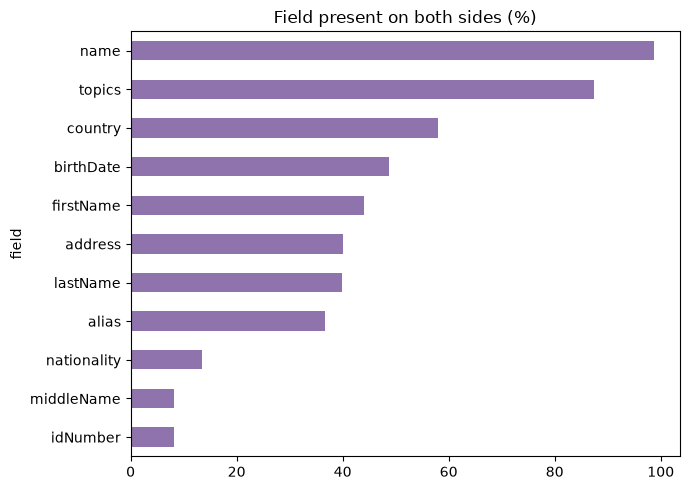

In [85]:
PROPS = ["name", "alias", "firstName", "lastName", "middleName", "birthDate",
         "country", "nationality", "idNumber", "address", "topics"]

presence = pd.DataFrame([
    {
        "field": p,
        "left %":  round(100 * (clean[f"left_{p}"].map(len) > 0).mean(), 1),
        "right %": round(100 * (clean[f"right_{p}"].map(len) > 0).mean(), 1),
        "both %":  round(100 * ((clean[f"left_{p}"].map(len) > 0)
                                & (clean[f"right_{p}"].map(len) > 0)).mean(), 1),
    }
    for p in PROPS
]).sort_values("both %", ascending=False).set_index("field")

print("A feature needs the field on BOTH sides to be computable.\n")
print(presence.to_string())

presence["both %"].plot.barh(figsize=(7, 5), color="#8F73AC")
plt.title("Field present on both sides (%)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [86]:
clean.head()

,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics,left_kind,right_kind
0,0,positive,eu-fsf-eu-3298-47,unsc-2894441,Person,Person,مثنى حارث سلمان الضاري,MUTHANNA HARITH SALMAN AL-DARI,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Abu Ghurayb, IRAQ, Khan Dari, I...","[Amman, Jordan, Asas Village, Iraq, Khan Dari,...",[sanction],[sanction],source,source
1,1,positive,ofac-11493,unsc-2894441,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, pl_finanse_sanctions, be_fod...",...,[iq],[iq],[],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction],source,source
2,2,positive,unsc-2894441,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",[ua_sfms_blacklist],...,[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Iraq, Asas Village, Abu Ghurayb...","[Amman, Jordan, Asas Village, Abu Ghurayb, Ira...",[sanction],[sanction],source,canonical
3,3,positive,gb-hmt-11052,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,MUTHANNA HARITH SALMAN AL-DARI,Muthanna Harith AL-DARI,[gb_hmt_sanctions],"[un_sc_sanctions, us_ofac_sdn, pl_finanse_sanc...",...,[iq],[iq],[1729765],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction],source,canonical
4,4,positive,eu-fsf-eu-2799-30,unsc-2971675,Person,Person,Abdurrahim Bashir,ABDUL RAHIM BA'AYSIR,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,[id],[id],[],[],[],[],[sanction],[sanction],source,source


In [87]:
clean[clean["right_caption"].fillna("").str.strip() == ""]

,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics,left_kind,right_kind


### 4.2 Does field presence differ between the two classes?

*If it does, missingness is itself a signal. We decide whether that is legitimate or leakage.*

In [88]:
rows = []
for p in PROPS:
    both = ((clean[f"left_{p}"].map(len) > 0)
            & (clean[f"right_{p}"].map(len) > 0))
    by = clean.assign(has=both).groupby("judgement").has.mean() * 100
    rows.append({"field": p,
                 "positive %": round(by.get("positive", 0), 1),
                 "negative %": round(by.get("negative", 0), 1),
                 "gap": round(by.get("positive", 0) - by.get("negative", 0), 1)})

gaps = (pd.DataFrame(rows).set_index("field")
        .reindex(pd.DataFrame(rows).set_index("field").gap.abs()
                 .sort_values(ascending=False).index))
print(gaps.to_string())

print("\nThese gaps are large, not marginal.")
print("Missingness predicts the label on its own, which makes it a leakage")
print("candidate: it describes which pairs an analyst was shown, not whether")
print("two entities are the same. Keep the indicators, but in part 7 measure")
print("what they contribute, and fit the model once with and once without.")

             positive %  negative %   gap
field                                    
country            38.4        86.3 -47.9
address            22.2        65.7 -43.5
alias              22.5        57.1 -34.5
birthDate          59.3        33.6  25.7
idNumber            1.0        18.5 -17.6
topics             81.0        97.0 -16.0
nationality         8.5        20.8 -12.3
firstName          48.9        36.9  12.1
lastName           44.3        33.6  10.7
middleName          4.6        13.5  -9.0
name               97.8       100.0  -2.2

These gaps are large, not marginal.
Missingness predicts the label on its own, which makes it a leakage
candidate: it describes which pairs an analyst was shown, not whether
two entities are the same. Keep the indicators, but in part 7 measure
what they contribute, and fit the model once with and once without.


### 4.3 What form do birth dates take?

*Check precision and whether one record can carry several. Decides whether date agreement is a boolean or a multi-level category.*

In [89]:
lengths = Counter(len(v) for lst in clean.left_birthDate for v in lst)
total = sum(lengths.values())

print("birthDate is stored as TEXT, at mixed precision:")
for n, label in [(10, "full date  1969-06-16"), (7, "year+month 1969-06"),
                 (4, "year only  1969")]:
    print(f"  {label:<24} {lengths.get(n, 0):>8,}  ({100*lengths.get(n,0)/total:.1f}%)")

multi = clean.left_birthDate.map(len) > 1
print(f"\nentities carrying more than one birth date: {100*multi.mean():.1f}%")
print("(different source lists disagreeing about the same person)")

print("\nExample of a record with several:")
ex = clean.loc[multi, "left_birthDate"].iloc[0]
print(" ", list(ex))

print("\nConsequence: '1969' vs '1969-06-16' is a PARTIAL match, not a conflict.")
print("Birth-date agreement must be four-way: exact / same year / conflict / missing.")

birthDate is stored as TEXT, at mixed precision:
  full date  1969-06-16     189,072  (75.5%)
  year+month 1969-06          1,609  (0.6%)
  year only  1969            59,713  (23.8%)

entities carrying more than one birth date: 9.4%
(different source lists disagreeing about the same person)

Example of a record with several:
  ['1969', '1969-06-16']

Consequence: '1969' vs '1969-06-16' is a PARTIAL match, not a conflict.
Birth-date agreement must be four-way: exact / same year / conflict / missing.


### 4.4 How many names does one entity carry?

*Decides whether to compare captions only or across the full alias lists.*

names per entity: median 1, p90 9, max 292
entities with only one name: 55.5%
entities with more than five: 16.0%


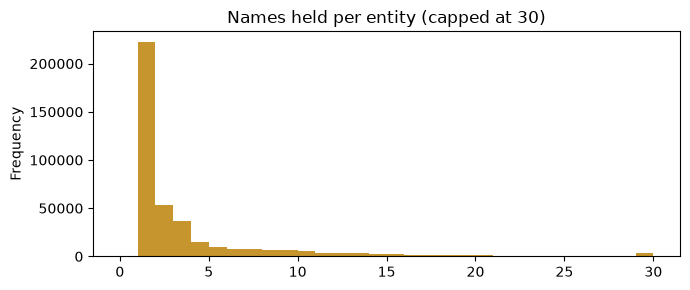


An entity with the most spellings:
  Mohammad Yahiya Moalla
  292 spellings, first five: ['ヤハヤー・ムアッラー・ムハンマド', "Mohammed Yehya MU'LA", 'Muhammad Yahya MOALLA', 'Mohammad Yahya MALA', 'Muhammad Yahiya MALA']

Comparing captions only throws all the other spellings away.
Whether that matters is question 4.5.


In [90]:
n_names = clean.left_name.map(len)

print(f"names per entity: median {n_names.median():.0f}, "
      f"p90 {n_names.quantile(0.9):.0f}, max {n_names.max():,}")
print(f"entities with only one name: {100 * (n_names == 1).mean():.1f}%")
print(f"entities with more than five: {100 * (n_names > 5).mean():.1f}%")

n_names.clip(upper=30).plot.hist(bins=30, figsize=(7, 3), color="#C7952D")
plt.title("Names held per entity (capped at 30)")
plt.tight_layout()
plt.show()

print("\nAn entity with the most spellings:")
most = clean.loc[n_names.idxmax()]
print(f"  {most.left_caption}")
print(f"  {len(most.left_name)} spellings, first five: {list(most.left_name)[:5]}")

print("\nComparing captions only throws all the other spellings away.")
print("Whether that matters is question 4.5.")

### 4.5 Is comparing across alias lists worth the extra cost?

*Measure it before building it. More spellings means more chances of a coincidental match too.*

In [91]:
sample = clean.sample(8_000, random_state=42)
y = (sample.judgement == "positive").astype(int)

def names_of(lst, caption):
    vals = [str(v) for v in lst][:12]          # cap: cost grows as n x m
    return vals or [str(caption)]

caption_score = np.array([fuzz.WRatio(a, b)
                          for a, b in zip(sample.left_caption, sample.right_caption)])

best_score = np.array([
    max((fuzz.WRatio(x, z) for x in names_of(ln, lc) for z in names_of(rn, rc)),
        default=0)
    for ln, rn, lc, rc in zip(sample.left_name, sample.right_name,
                              sample.left_caption, sample.right_caption)
])

auc_cap = roc_auc_score(y, caption_score)
auc_best = roc_auc_score(y, best_score)

print(f"AUC, captions only          : {auc_cap:.3f}")
print(f"AUC, best across all names  : {auc_best:.3f}")
print(f"gain                        : {auc_best - auc_cap:+.3f}")

print(f"\nmean lift on positives: {(best_score - caption_score)[y == 1].mean():+.1f} points")
print(f"mean lift on negatives: {(best_score - caption_score)[y == 0].mean():+.1f} points")
print("\nIt lifts negatives too: more spellings means more chances of a")
print("coincidental match. Cheap enough to keep, but it will not carry the model.")

AUC, captions only          : 0.650
AUC, best across all names  : 0.666
gain                        : +0.016

mean lift on positives: +11.6 points
mean lift on negatives: +20.5 points

It lifts negatives too: more spellings means more chances of a
coincidental match. Cheap enough to keep, but it will not carry the model.


---

# 5. Where is the difficulty?

This is the part that produces the findings worth presenting.

### 5.1 How well does a simple name-similarity score separate the two classes?

*Plot both distributions on the same axes. The region where they overlap is the whole problem.*

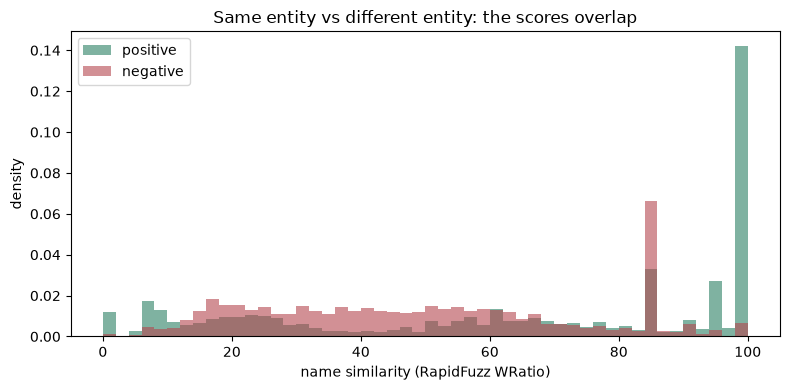

            25%   50%    75%
judgement                   
negative   28.4  48.0   68.4
positive   29.2  73.1  100.0

AUC of this single score: 0.649
pairs in the ambiguous 60-95 band: 28.5%
different entities scoring a perfect 100: 1.29%

The overlap region IS the problem. No threshold on this score splits
it without making one kind of mistake or the other.


In [92]:
sample = clean.sample(60_000, random_state=42).copy()
sample["sim"] = [fuzz.WRatio(a, b)
                 for a, b in zip(sample.left_caption, sample.right_caption)]
y = (sample.judgement == "positive").astype(int)

fig, ax = plt.subplots(figsize=(8, 4))
for label, colour in [("positive", "#2a7f62"), ("negative", "#b4474e")]:
    ax.hist(sample.loc[sample.judgement == label, "sim"],
            bins=50, alpha=0.6, density=True, label=label, color=colour)
ax.set_xlabel("name similarity (RapidFuzz WRatio)")
ax.set_ylabel("density")
ax.set_title("Same entity vs different entity: the scores overlap")
ax.legend()
plt.tight_layout()
plt.show()

print(sample.groupby("judgement").sim.describe()[["25%", "50%", "75%"]].round(1).to_string())
print(f"\nAUC of this single score: {roc_auc_score(y, sample.sim):.3f}")
print(f"pairs in the ambiguous 60-95 band: "
      f"{100 * ((sample.sim > 60) & (sample.sim < 95)).mean():.1f}%")
print(f"different entities scoring a perfect 100: "
      f"{100 * (sample.loc[sample.judgement == 'negative', 'sim'] == 100).mean():.2f}%")
print("\nThe overlap region IS the problem. No threshold on this score splits")
print("it without making one kind of mistake or the other.")

### 5.2 Are there pairs with identical names that are different entities?

*If so, no string metric can ever separate them. Check whether any other field can.*

In [116]:
identical = (clean.left_caption.str.strip().str.casefold()
             == clean.right_caption.str.strip().str.casefold())
neg_identical = clean[identical & (clean.judgement == "negative")]

print(f"pairs with identical names      : {identical.sum():,}")
print(f"  of which DIFFERENT entities   : {len(neg_identical):,} "
      f"({100 * len(neg_identical) / identical.sum():.1f}%)")
print("\nNo string metric can ever separate these. They are a hard floor under")
print("the error rate of any name-only approach.")

def bd_state(left, right):
    L, R = set(left), set(right)
    if not L or not R:                              return "missing"
    if L & R:                                       return "exact"
    if {v[:4] for v in L} & {v[:4] for v in R}:     return "same year"
    return "conflict"

states = pd.Series([bd_state(l, r) for l, r in
                    zip(neg_identical.left_birthDate, neg_identical.right_birthDate)])
print("\nCan a birth date rescue them?")
print(states.value_counts().to_string())
have = 100 * (states != "missing").mean()
print(f"\nOnly {have:.0f}% carry a birth date on both sides.")
print(f"For the other {100-have:.0f}% NOTHING in this dataset separates them.")
print("\nThat is the operational finding: the fix is not a better algorithm,")
print("it is collecting a date of birth at onboarding.")

print("\nTen of them:")
print(neg_identical[["left_caption", "right_caption", "left_schema", "right_schema"]].head(10).to_string(index=False))

pairs with identical names      : 130,525
  of which DIFFERENT entities   : 3,083 (2.4%)

No string metric can ever separate these. They are a hard floor under
the error rate of any name-only approach.

Can a birth date rescue them?
missing      2906
conflict      121
same year      37
exact          19

Only 6% carry a birth date on both sides.
For the other 94% NOTHING in this dataset separates them.

That is the operational finding: the fix is not a better algorithm,
it is collecting a date of birth at onboarding.

Ten of them:
                  left_caption                  right_caption  left_schema right_schema
            Hassan Dahir AWEYS             Hassan Dahir AWEYS       Person       Person
            HASSAN DAHIR AWEYS             Hassan Dahir AWEYS       Person       Person
            Hassan Dahir AWEYS             HASSAN DAHIR AWEYS       Person       Person
                   ZAFAR IQBAL                    Zafar IQBAL       Person       Person
                   ZAFA

### 5.3 Are company and organisation pairs different from person pairs?

*Company names carry legal suffixes shared by unrelated firms. Check whether the two behave the same.*

In [117]:
sample["kind"] = np.where(sample.left_schema == "Person", "Person", "Company/Org")

rows = []
for kind, g in sample.groupby("kind"):
    rows.append({
        "kind": kind,
        "pairs": f"{len(g):,}",
        "% positive": round(100 * (g.judgement == "positive").mean(), 1),
        "median score, positives": round(g.loc[g.judgement == "positive", "sim"].median(), 1),
        "median score, negatives": round(g.loc[g.judgement == "negative", "sim"].median(), 1),
        "AUC": round(roc_auc_score((g.judgement == "positive").astype(int), g.sim), 3),
    })
print(pd.DataFrame(rows).set_index("kind").to_string())

print("\nFor companies the name score is barely better than a coin toss, and the")
print("median score for TRUE matches is lower than for non-matches.")
print("\nWhy: legal suffixes. The commonest tokens in the whole database are")
print("shared by millions of unrelated firms:")
print(freq_tokens.head(12).to_string())
print("\nStrip them before scoring, and never report people and companies as")
print("one number.")

              pairs  % positive  median score, positives  median score, negatives    AUC
kind                                                                                    
Company/Org  20,579        39.9                     36.4                     39.7  0.538
Person       39,421        68.9                     75.9                     53.3  0.670

For companies the name score is barely better than a coin toss, and the
median score for TRUE matches is lower than for non-matches.

Why: legal suffixes. The commonest tokens in the whole database are
shared by millions of unrelated firms:
of                  197203
общество             96537
с                    85910
ограниченной         75511
ответственностью     74938
de                   62570
ltd.                 61931
co.,                 59263
mayor                55660
municipal            36713
the                  34750
and                  32288

Strip them before scoring, and never report people and companies as
one numbe

### 5.4 What happens on pairs written in two different alphabets?

*Measure the score's behaviour there rather than assuming. Then test whether simple normalisation helps.*

In [120]:
def script_of(text):
    """Rough writing system, from the first few letters."""
    names = []
    for ch in str(text):
        if not ch.isalpha():
            continue
        try:
            names.append(unicodedata.name(ch).split()[0])
        except ValueError:
            names.append("UNKNOWN")
        if len(names) >= 8:
            break
    if not names:
        return "none"
    return max(set(names), key=names.count).title()

sample["ls"] = sample.left_caption.map(script_of)
sample["rs"] = sample.right_caption.map(script_of)
cross = sample.ls != sample.rs

print(f"pairs mixing two writing systems: {100 * cross.mean():.1f}%")
print("\nscript of the left-hand name:")
print((sample.ls.value_counts(normalize=True).head(5) * 100).round(2).to_string())

print("\nscript of the right-hand name:")
print((sample.rs.value_counts(normalize=True).head(5) * 100).round(2).to_string())

auc_same = roc_auc_score((sample.loc[~cross, "judgement"] == "positive").astype(int),
                         sample.loc[~cross, "sim"])
auc_cross = roc_auc_score((sample.loc[cross, "judgement"] == "positive").astype(int),
                          sample.loc[cross, "sim"])
print(f"\nAUC on same-script pairs : {auc_same:.3f}")
print(f"AUC on cross-script pairs: {auc_cross:.3f}")

# does simple normalisation help?
def strip_accents(s):
    s = unicodedata.normalize("NFKD", str(s))
    return "".join(c for c in s if not unicodedata.combining(c))

cs = sample[cross]
sim_t = [fuzz.WRatio(strip_accents(a), strip_accents(b))
         for a, b in zip(cs.left_caption, cs.right_caption)]
auc_t = roc_auc_score((cs.judgement == "positive").astype(int), sim_t)
print(f"after stripping accents  : {auc_t:.3f}")

print("\nBelow 0.5 means the score points the WRONG way there: any resemblance")
print("between a Cyrillic and a Latin string is coincidence. Accent-stripping")
print("does not bridge alphabets. Real transliteration is a step-4 decision;")
print("for now add a cross_script flag so the model can distrust the score.")

pairs mixing two writing systems: 6.9%

script of the left-hand name:
ls
Latin       89.25
Cyrillic     9.89
Cjk          0.66
Arabic       0.14
Thai         0.02

script of the right-hand name:
rs
Latin       93.38
Cyrillic     6.09
Cjk          0.38
Arabic       0.12
Hangul       0.01

AUC on same-script pairs : 0.719
AUC on cross-script pairs: 0.475
after stripping accents  : 0.480

Below 0.5 means the score points the WRONG way there: any resemblance
between a Cyrillic and a Latin string is coincidence. Accent-stripping
does not bridge alphabets. Real transliteration is a step-4 decision;
for now add a cross_script flag so the model can distrust the score.


### 5.5 Does how common a name is relate to difficulty?

*Use names.txt for frequency. This is what the second dataset is for; confirm it earns its place.*

                   pairs  % ambiguous  % negative
band                                             
unknown              858         10.6        12.9
rare (1-10)        20467         27.7        28.8
uncommon (11-100)  13699         33.1        39.7
common (101-1k)    12515         29.7        52.2
very common (>1k)  12461         24.7        53.4

The trend is monotone: the commoner the surname, the more likely a
candidate pair is a coincidence. Name frequency earns its place as a
feature, and this is what the second dataset is for.

Caveat for the report: we approximate 'surname' by the last token,
which is wrong for several naming conventions and for organisations.


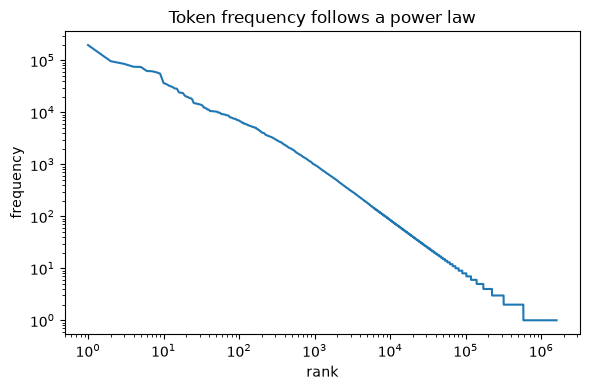

In [96]:
def last_token_freq(caption):
    toks = str(caption).casefold().split()
    return freq_tokens.get(toks[-1], 0) if toks else 0

sample["name_freq"] = sample.left_caption.map(last_token_freq)
sample["band"] = pd.cut(sample.name_freq, [-1, 0, 10, 100, 1000, 10**9],
                        labels=["unknown", "rare (1-10)", "uncommon (11-100)",
                                "common (101-1k)", "very common (>1k)"])

ambiguous = (sample.sim > 60) & (sample.sim < 95)
cats = list(sample.band.cat.categories)
table = pd.DataFrame({
    "pairs": sample.band.value_counts().reindex(cats),
    "% ambiguous": (sample.assign(a=ambiguous).groupby("band", observed=False)
                    .a.mean().reindex(cats) * 100).round(1),
    "% negative": (sample.assign(n=sample.judgement == "negative")
                   .groupby("band", observed=False).n.mean().reindex(cats) * 100).round(1),
})
print(table.to_string())

print("\nThe trend is monotone: the commoner the surname, the more likely a")
print("candidate pair is a coincidence. Name frequency earns its place as a")
print("feature, and this is what the second dataset is for.")
print("\nCaveat for the report: we approximate 'surname' by the last token,")
print("which is wrong for several naming conventions and for organisations.")

# Zipf: the reason rarity carries so much information
plt.figure(figsize=(6, 4))
plt.loglog(range(1, len(freq_tokens) + 1), freq_tokens.values)
plt.xlabel("rank"); plt.ylabel("frequency")
plt.title("Token frequency follows a power law")
plt.tight_layout()
plt.show()

---

# 6. Is this one problem or two?

### 6.1 Split everything by whether a birth date exists on both sides

*Recompute the balance, the score distributions and the difficulty separately for each half.*

judgement  negative  positive    rows
bd                                   
conflict       98.8       1.2   50033
exact           2.8      97.2  136407
missing        53.0      47.0  205064
same year      20.0      80.0    9094

Read the 'missing' row: the classes are nearly even there. That is the
half of the data where names are all you have.

                     pairs  % positive  AUC of name score
half                                                     
birth date present  29,375        71.7              0.776
no birth date       30,625        46.7              0.517


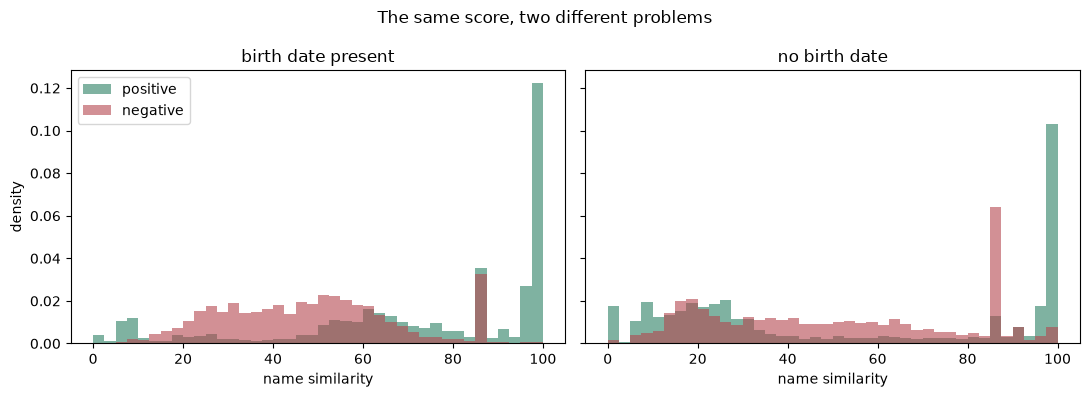

In [98]:
clean["bd"] = [bd_state(l, r) for l, r in
               zip(clean.left_birthDate, clean.right_birthDate)]

table = pd.crosstab(clean.bd, clean.judgement)
pct = (table.div(table.sum(axis=1), axis=0) * 100).round(1)
pct["rows"] = table.sum(axis=1)
print(pct.to_string())

print("\nRead the 'missing' row: the classes are nearly even there. That is the")
print("half of the data where names are all you have.")

sample["bd"] = [bd_state(l, r) for l, r in
                zip(sample.left_birthDate, sample.right_birthDate)]
sample["half"] = np.where(sample.bd == "missing", "no birth date", "birth date present")

rows = []
for half, g in sample.groupby("half"):
    rows.append({"half": half, "pairs": f"{len(g):,}",
                 "% positive": round(100 * (g.judgement == "positive").mean(), 1),
                 "AUC of name score": round(roc_auc_score(
                     (g.judgement == "positive").astype(int), g.sim), 3)})
print("\n" + pd.DataFrame(rows).set_index("half").to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (half, g) in zip(axes, sample.groupby("half")):
    for label, colour in [("positive", "#2a7f62"), ("negative", "#b4474e")]:
        ax.hist(g.loc[g.judgement == label, "sim"], bins=40, alpha=.6,
                density=True, label=label, color=colour)
    ax.set_title(half); ax.set_xlabel("name similarity")
axes[0].set_ylabel("density"); axes[0].legend()
fig.suptitle("The same score, two different problems")
plt.tight_layout()
plt.show()

### 6.2 If one half is harder, is that the metric's fault or the data's?

*Try several different string metrics on the same split. If they all agree, it is the data.*

In [99]:
metrics = {
    "WRatio":           fuzz.WRatio,
    "ratio":            fuzz.ratio,
    "token_sort_ratio": fuzz.token_sort_ratio,
    "token_set_ratio":  fuzz.token_set_ratio,
    "partial_ratio":    fuzz.partial_ratio,
    "Jaro-Winkler":     lambda a, b: rf_distance.JaroWinkler.similarity(a, b) * 100,
}

easy = sample[sample.bd != "missing"]
hard = sample[sample.bd == "missing"]

rows = []
for name, fn in metrics.items():
    rows.append({
        "metric": name,
        "AUC, birth date": round(roc_auc_score(
            (easy.judgement == "positive").astype(int),
            [fn(a, b) for a, b in zip(easy.left_caption, easy.right_caption)]), 3),
        "AUC, no birth date": round(roc_auc_score(
            (hard.judgement == "positive").astype(int),
            [fn(a, b) for a, b in zip(hard.left_caption, hard.right_caption)]), 3),
    })
print(pd.DataFrame(rows).set_index("metric").to_string())
print("\nEvery metric lands in the same place, so it is the data, not the metric.")

hard_person = hard[hard.left_schema == "Person"]
auc_hp = roc_auc_score((hard_person.judgement == "positive").astype(int), hard_person.sim)
print(f"\nPerson pairs with no birth date: AUC {auc_hp:.3f}  (n={len(hard_person):,})")
print("Below 0.5. A MORE similar name makes the pair MORE likely to be two")
print("different people.")

# Does token structure survive where character matching does not?
def tokens(s):
    return set(str(s).casefold().split())

jacc = [len(tokens(a) & tokens(b)) / max(len(tokens(a) | tokens(b)), 1)
        for a, b in zip(hard_person.left_caption, hard_person.right_caption)]
print(f"\ntoken Jaccard on the same pairs : AUC "
      f"{roc_auc_score((hard_person.judgement == 'positive').astype(int), jacc):.3f}")
print("\nSo it is CHARACTER-level matching that fails, not names. The candidate")
print("generator already spent the character signal when it chose which pairs")
print("to propose; token structure survives because it never used it.")

                  AUC, birth date  AUC, no birth date
metric                                               
WRatio                      0.776               0.517
ratio                       0.777               0.542
token_sort_ratio            0.807               0.545
token_set_ratio             0.803               0.537
partial_ratio               0.808               0.525
Jaro-Winkler                0.795               0.553

Every metric lands in the same place, so it is the data, not the metric.

Person pairs with no birth date: AUC 0.409  (n=10,046)
Below 0.5. A MORE similar name makes the pair MORE likely to be two
different people.

token Jaccard on the same pairs : AUC 0.760

So it is CHARACTER-level matching that fails, not names. The candidate
generator already spent the character signal when it chose which pairs
to propose; token structure survives because it never used it.


### 6.3 Decide: one model or two?

*Write the decision and the reason. This shapes steps 4 and 5 of the project.*

In [121]:
print("""DECISION: one model, two reports.

Birth-date agreement enters as a four-level categorical feature
(exact / same year / conflict / missing), not a boolean and not a split.

Why one model:
  - two models halve the training data for each
  - two models mean two thresholds, two feature sets, two error taxonomies,
    maintained by two people in a course project
  - a tree model will learn the split by itself; the signal is enormous

Why two reports:
  - the two halves are genuinely different problems (6.1, 6.2)
  - a single combined cost curve would hide that character matching is
    near-useless on half the traffic
  - the operational recommendation falls out of the comparison

What we do NOT do: report one combined number.""")

DECISION: one model, two reports.

Birth-date agreement enters as a four-level categorical feature
(exact / same year / conflict / missing), not a boolean and not a split.

Why one model:
  - two models halve the training data for each
  - two models mean two thresholds, two feature sets, two error taxonomies,
    maintained by two people in a course project
  - a tree model will learn the split by itself; the signal is enormous

Why two reports:
  - the two halves are genuinely different problems (6.1, 6.2)
  - a single combined cost curve would hide that character matching is
    near-useless on half the traffic
  - the operational recommendation falls out of the comparison

What we do NOT do: report one combined number.


---

# 7. Leakage check

The last thing before feature engineering, and the easiest to skip. Some
columns describe how the dataset was assembled rather than who the entities
are. A model given those looks excellent and means nothing.

### 7.0 Prove the leakage mechanism, not only correlation.

*High AUC is a symptom. We can exclude the column only by understanding WHY.*

In [101]:
# HYPOTHESIS: some columns leak - they describe how the dataset was built,
# not who the entities are. Before excluding anything, prove the mechanism.

from sklearn.metrics import roc_auc_score
y = (clean.judgement == "positive").astype(int).values

# --- the claim: records from the SAME source list are usually DIFFERENT people
shared = np.array([len(set(a) & set(b)) > 0
                   for a, b in zip(clean.left_datasets, clean.right_datasets)])
print("do the two records share a source list?")
print(pd.crosstab(shared, clean.judgement, normalize="index").round(3).to_string())
print(f"\nAUC using ONLY this, reading no name: "
      f"{roc_auc_score(y, (~shared).astype(float)):.3f}")

print("""
WHY. Deduplication merges records ACROSS source lists, and one list does not
normally contain the same entity twice. So "same list" implies "different
entity" almost mechanically. The column describes the labelling process.
""")

# --- a feature that leaks the other way
n_names = clean.left_name.map(len).values.astype(float)
auc_names = roc_auc_score(y, n_names)
print(f"AUC of 'how many names the left record holds': {auc_names:.3f}")
print(f"  strength = max(AUC, 1-AUC) = {max(auc_names, 1-auc_names):.3f}, "
      f"pointing at {'same' if auc_names > .5 else 'different'} entity")
print("Same mechanism: a merged entity accumulates spellings.")

# --- the control: a feature that genuinely describes the entities
from rapidfuzz import fuzz
chk = clean.sample(20_000, random_state=0)
name_score = [fuzz.WRatio(a, b) for a, b in zip(chk.left_caption, chk.right_caption)]
print(f"\nfor comparison, an honest feature (name similarity): "
      f"AUC {roc_auc_score((chk.judgement=='positive').astype(int), name_score):.3f}")
print("\nThe leaky columns beat the thing we are actually trying to measure.")
print("That is the tell.")

do the two records share a source list?
judgement  negative  positive
row_0                        
False         0.050     0.950
True          0.882     0.118

AUC using ONLY this, reading no name: 0.922

WHY. Deduplication merges records ACROSS source lists, and one list does not
normally contain the same entity twice. So "same list" implies "different
entity" almost mechanically. The column describes the labelling process.

AUC of 'how many names the left record holds': 0.185
  strength = max(AUC, 1-AUC) = 0.815, pointing at different entity
Same mechanism: a merged entity accumulates spellings.

for comparison, an honest feature (name similarity): AUC 0.658

The leaky columns beat the thing we are actually trying to measure.
That is the tell.


### 7.1 Can anything predict the label without reading the names at all?

*Test each suspect column on its own. Watch for features that point the *wrong* way: they are just as predictive.*

In [122]:
y = (clean.judgement == "positive").astype(int).values
candidates = {}

shared_source = np.array([len(set(a) & set(b)) > 0
                          for a, b in zip(clean.left_datasets, clean.right_datasets)])
candidates["shares a source list"] = (~shared_source).astype(float)
candidates["number of source lists (left)"] = -clean.left_datasets.map(len).values.astype(float)
# id type: workflow metadata, measured here so the exclusion is evidenced
import re as _re
def _kind(v):
    v = str(v)
    return 1.0 if (v.startswith("NK-") or _re.match(r"^Q\d+$", v)) else 0.0

lk = clean.left_id.map(_kind).values
rk = clean.right_id.map(_kind).values
candidates["both sides are merged entities"] = (lk * rk)
candidates["exactly one side is a merged entity"] = (lk != rk).astype(float)
candidates["number of merged sides (0, 1 or 2)"] = lk + rk
candidates["number of names held (left)"] = clean.left_name.map(len).values.astype(float)
candidates["left is sanctioned (topics)"] = clean.left_topics.map(
    lambda t: "sanction" in t).values.astype(float)
candidates["schemas identical"] = (clean.left_schema == clean.right_schema).values.astype(float)
for prop in ("country", "address", "idNumber", "birthDate"):
    candidates[f"{prop} present both sides"] = (
        (clean[f"left_{prop}"].map(len) > 0)
        & (clean[f"right_{prop}"].map(len) > 0)).values.astype(float)

rows = []
for name, score in candidates.items():
    auc = roc_auc_score(y, score)
    rows.append({"candidate": name,
                 "AUC": round(auc, 3),
                 "strength": round(max(auc, 1 - auc), 3),
                 "points to": "same entity" if auc >= 0.5 else "different entity"})

leak = pd.DataFrame(rows).sort_values("strength", ascending=False).set_index("candidate")
print("None of these reads a name.\n")
print(leak.to_string())

print("\n'strength' is max(AUC, 1-AUC): a feature at AUC 0.18 is exactly as")
print("predictive as one at 0.82, it just points the other way. Sorting on raw")
print("AUC would have hidden half of them.")

None of these reads a name.

                                       AUC  strength         points to
candidate                                                             
exactly one side is a merged entity  0.942     0.942       same entity
shares a source list                 0.922     0.922       same entity
number of source lists (left)        0.901     0.901       same entity
both sides are merged entities       0.109     0.891  different entity
number of merged sides (0, 1 or 2)   0.158     0.842  different entity
number of names held (left)          0.185     0.815  different entity
left is sanctioned (topics)          0.211     0.789  different entity
country present both sides           0.260     0.740  different entity
address present both sides           0.282     0.718  different entity
birthDate present both sides         0.629     0.629       same entity
idNumber present both sides          0.412     0.588  different entity
schemas identical                    0.524     0

### 7.2 Which candidates must be excluded, and which are borderline?

*For each one, say what mechanism makes it leaky. If we cannot explain the mechanism, we have not found a leak yet.*

In [103]:
print("""EXCLUDE - these describe how the data was assembled:

  left_datasets / right_datasets
      Deduplication merges records ACROSS source lists, and one list does not
      normally contain the same entity twice. So "same list" implies "different
      entity" almost mechanically. Predicts the label at ~92% with no name.

  number of source lists held
      The same signal in another shape: an entity on many lists was merged
      from many lists.

  topics
      Says why an entity was listed (sanction, PEP, crime), not who it is.
      Two unrelated sanctioned people share it; it carries no identity signal.

  number of names held
      Same mechanism again: a merged entity accumulates spellings.

KEEP, BUT MEASURE SEPARATELY - field-presence indicators:

  country / address / idNumber / birthDate present on both sides
      These predict the label well above chance. Partly legitimate: a real
      screening system also knows which fields it holds, and a missing field
      genuinely changes how confident you can be. Partly an artefact of which
      pairs an analyst was shown.
      We cannot separate the two parts, so: fit the model once with these and
      once without, report both, and say plainly that the difference is an
      upper bound on how much of our performance comes from the sampling
      process rather than from the entities.

THE TEST we used, for the report:
  a column is process-describing if you could fill it in without knowing
  anything about the person.""")

EXCLUDE - these describe how the data was assembled:

  left_datasets / right_datasets
      Deduplication merges records ACROSS source lists, and one list does not
      normally contain the same entity twice. So "same list" implies "different
      entity" almost mechanically. Predicts the label at ~92% with no name.

  number of source lists held
      The same signal in another shape: an entity on many lists was merged
      from many lists.

  topics
      Says why an entity was listed (sanction, PEP, crime), not who it is.
      Two unrelated sanctioned people share it; it carries no identity signal.

  number of names held
      Same mechanism again: a merged entity accumulates spellings.

KEEP, BUT MEASURE SEPARATELY - field-presence indicators:

  country / address / idNumber / birthDate present on both sides
      These predict the label well above chance. Partly legitimate: a real
      screening system also knows which fields it holds, and a missing field
      genuinely ch

---

# 8. Wrap up

### 8.0a What must the split guarantee, and what counts as one entity?

*The split decides whether every later number means anything, and it cannot be repaired afterwards. The only real decision is which rows count as a link between two ids.*


In [104]:
# The split must guarantee one thing: no id appears in two different splits.
# If it does, the model memorises that id while training and meets it again at
# test time, and the test number stops measuring generalisation and starts
# measuring memory.
#
# That rules out throwing rows into splits independently. Ids have to be
# grouped first, and whole groups sent to one split. The grouping rule is the
# decision, and it reduces to a single question: which rows count as a link
# between two ids?
#
#   Option A - every row is a link.
#       Reads as: "these two ids were compared to each other."
#       A group is then a pile of ids that happened to get compared, which is
#       not an entity.
#
#   Option B - only positive rows are links.
#       Reads as: "an analyst decided these two ids are the same entity."
#       Chains count: A=B and B=C means A, B, C are one entity.
#       A group is then an entity, which is exactly the thing we must not
#       split across train and test.
#
# Both are measured here, because the difference turns out to be large.

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

left = clean.left_id.astype(str)
right = clean.right_id.astype(str)
entities = pd.Index(pd.unique(pd.concat([left, right])))
row_of = {e: i for i, e in enumerate(entities)}
li = left.map(row_of).to_numpy()
ri = right.map(row_of).to_numpy()
n_ent = len(entities)
is_pos = (clean.judgement == "positive").to_numpy()

def group_ids(link_mask):
    """Group ids, using only the rows selected by link_mask as links."""
    graph = coo_matrix((np.ones(int(link_mask.sum())),
                        (li[link_mask], ri[link_mask])),
                       shape=(n_ent, n_ent))
    return connected_components(graph, directed=False)

def evaluate(name, link_mask, seed=42):
    n_groups, group_of = group_ids(link_mask)
    sizes = pd.Series(group_of).value_counts()

    rng = np.random.default_rng(seed)
    u = rng.random(n_groups)
    where = np.where(u < 0.6, "train", np.where(u < 0.8, "val", "test"))
    ls, rs = where[group_of[li]], where[group_of[ri]]
    keep = ls == rs

    print(f"--- {name}")
    print(f"    groups                : {n_groups:,}")
    print(f"    group size            : median {sizes.median():.0f}, "
          f"95th {sizes.quantile(0.95):.0f}, max {sizes.max():,} "
          f"({100*sizes.max()/n_ent:.2f}% of ids)")
    print(f"    rows kept             : {keep.sum():,} / {len(clean):,} "
          f"({100*keep.mean():.1f}%)")
    dropped_pos = int((is_pos & ~keep).sum())
    print(f"    rows dropped          : {int((~keep).sum()):,} "
          f"(positive {dropped_pos:,}, negative {int((~keep).sum())-dropped_pos:,})")
    parts = []
    for s in ("train", "val", "test"):
        sel = keep & (ls == s)
        share = 100 * is_pos[sel].mean() if sel.sum() else float("nan")
        parts.append(f"{s} {100*sel.sum()/max(keep.sum(),1):.0f}%/pos {share:.0f}%")
    print(f"    split size / balance  : " + "   ".join(parts))
    return n_groups, group_of

all_rows = np.ones(len(clean), dtype=bool)
print("Option A, every row is a link:\n")
nA, gA = evaluate("every row", all_rows)
print("\nOption B, only positive rows are links:\n")
nB, gB = evaluate("positive rows only", is_pos)

print("""
Reading: Option A keeps every row, because a row can never straddle two
groups when the row itself is a link. The cost is not lost rows, it is that
one group swallows roughly a quarter of all ids, lands whole in one split,
and wrecks both the split sizes and the label balance. Option B loses the
rows that connect two different entities, every one of them a negative, and
in exchange its groups are entity-sized and the splits are usable.
""")


Option A, every row is a link:

--- every row
    groups                : 140,274
    group size            : median 2, 95th 3, max 96,595 (23.47% of ids)
    rows kept             : 400,598 / 400,598 (100.0%)
    rows dropped          : 0 (positive 0, negative 0)
    split size / balance  : train 27%/pos 94%   val 65%/pos 40%   test 9%/pos 94%

Option B, only positive rows are links:

--- positive rows only
    groups                : 174,812
    group size            : median 2, 95th 4, max 36 (0.01% of ids)
    rows kept             : 307,676 / 400,598 (76.8%)
    rows dropped          : 92,922 (positive 0, negative 92,922)
    split size / balance  : train 64%/pos 71%   val 18%/pos 87%   test 18%/pos 88%

Reading: Option A keeps every row, because a row can never straddle two
groups when the row itself is a link. The cost is not lost rows, it is that
one group swallows roughly a quarter of all ids, lands whole in one split,
and wrecks both the split sizes and the label balance. Opt

### 8.0b Why does treating every row as a link produce one enormous group?

*Understand the mechanism before working around it, because the same mechanism will appear again in feature engineering.*


In [123]:
# Option A produced one group holding about a quarter of all ids. That is not
# an accident of this dataset, it is what negative rows do to a graph.
#
# A negative row says "these two are different". Used as a link it still joins
# them. A record with a common name gets compared against many different
# candidates, so it becomes a hub; two hubs sharing any candidate merge; and
# the merges cascade until a large share of the data is one blob.

deg = pd.Series(np.concatenate([li, ri])).value_counts()
deg_pos = pd.Series(np.concatenate([li[is_pos], ri[is_pos]])).value_counts()

print("rows an id takes part in (all rows vs positive rows only):")
print(pd.DataFrame({
    "all rows": deg.describe(percentiles=[0.5, 0.99]).round(1),
    "positive only": deg_pos.describe(percentiles=[0.5, 0.99]).round(1),
}).to_string())

busiest = deg.head(5).index
print("\nthe five busiest ids, and how their rows are labelled:")
for pos_i in busiest:
    ident = entities[pos_i]
    touches = (li == pos_i) | (ri == pos_i)
    n_pos = int((touches & is_pos).sum())
    cap = clean.loc[(clean.left_id.astype(str) == ident), "left_caption"]
    if cap.empty:
        cap = clean.loc[(clean.right_id.astype(str) == ident), "right_caption"]
    name = cap.iloc[0] if len(cap) else "?"
    print(f"   {ident:<28} rows {int(touches.sum()):>4}  "
          f"positive {n_pos:>4}  negative {int(touches.sum())-n_pos:>4}  {name[:38]}")

sizes_A = pd.Series(gA).value_counts()
sizes_B = pd.Series(gB).value_counts()
print(f"\nlargest group: {sizes_A.max():,} ids when every row links, "
      f"{sizes_B.max():,} ids when only positive rows link")
print("Negative rows are what glue unrelated entities together, so they must")
print("not be used as links. They are still kept as training rows.")


rows an id takes part in (all rows vs positive rows only):
       all rows  positive only
count  411639.0       390838.0
mean        1.9            1.2
std         4.8            1.1
min         1.0            1.0
50%         1.0            1.0
99%        27.0            6.0
max       179.0           21.0

the five busiest ids, and how their rows are labelled:
   NK-nXLmzkpmQp96ZWujMYTamk    rows  179  positive   19  negative  160  REVIVAL OF ISLAMIC HERITAGE SOCIETY
   NK-V35KzbZu3Emo8vCm3vj547    rows  175  positive   10  negative  165  Federal State Budgetary Enterprise ‘Pr
   NK-hMqExnoAzGQNVvJcs3oJho    rows  155  positive    7  negative  148  State Unitary Enterprise of the Republ
   NK-CNtajKD75HPcro3jTED8En    rows  137  positive   10  negative  127  Russian National Commercial Bank
   NK-GJTBw2WaHRSrARq5bAxnF5    rows  137  positive    9  negative  128  The Islamic Republic of Iran Shipping 

largest group: 96,595 ids when every row links, 36 ids when only positive rows link
N

### 8.0c Build and save the split

*Groups come from positive rows only. Whole groups go to one split. Rows crossing two groups are dropped and counted.*


In [106]:
# Build the split we will actually use: groups from positive rows only.

GROUP_LINKS = "positive"      # "positive" (chosen) or "all" (see 8.0a)
SPLIT_SEED = 42

link_mask = is_pos if GROUP_LINKS == "positive" else np.ones(len(clean), bool)
n_groups, group_of = group_ids(link_mask)

rng = np.random.default_rng(SPLIT_SEED)
u = rng.random(n_groups)
group_split = np.where(u < 0.6, "train", np.where(u < 0.8, "val", "test"))

ls, rs = group_split[group_of[li]], group_split[group_of[ri]]
keep = ls == rs

split_df = clean[keep].copy()
split_df["split"] = ls[keep]
split_df["entity_group"] = group_of[li][keep]

print(f"entities (groups)   : {n_groups:,}")
print(f"rows kept           : {len(split_df):,} / {len(clean):,} "
      f"({100*keep.mean():.1f}%)")
print(f"rows dropped        : {int((~keep).sum()):,}, of which positive "
      f"{int((is_pos & ~keep).sum()):,}")
print()
summary = (split_df.assign(positive=split_df.judgement.eq("positive"))
           .groupby("split")
           .agg(rows=("judgement", "size"),
                positive_share=("positive", "mean"),
                entities=("entity_group", "nunique")))
summary["share_of_rows"] = summary.rows / summary.rows.sum()
print(summary.to_string(float_format=lambda v: f"{v:.3f}"))

# The guarantee, asserted rather than assumed.
grp = pd.DataFrame({"group": np.concatenate([group_of[li][keep],
                                             group_of[ri][keep]]),
                    "split": np.concatenate([split_df.split.to_numpy(),
                                             split_df.split.to_numpy()])})
leaked = grp.groupby("group").split.nunique()
assert (leaked == 1).all(), "a group appears in more than one split"
print("\ncheck passed: no entity group appears in more than one split")

# Known remaining weakness, stated rather than hidden: the label balance is
# not equal across splits. Dropped rows are all negative, and a negative row
# survives far more often inside train (0.6 x 0.6) than inside test
# (0.2 x 0.2), so train retains proportionally more negatives. This is a
# property of the split, not of the entities, and it has to be handled when
# the operating threshold is chosen - by class weighting or by reporting
# false-alarm counts per 10,000 pairs rather than as a raw rate.

SPLIT_PATH = C.DATA_PROCESSED / "pairs_split.parquet"
SPLIT_PATH.parent.mkdir(parents=True, exist_ok=True)
split_df.to_parquet(SPLIT_PATH, index=False)
print(f"\nwritten: {SPLIT_PATH}  ({len(split_df):,} rows)")


entities (groups)   : 174,812
rows kept           : 307,676 / 400,598 (76.8%)
rows dropped        : 92,922, of which positive 0

         rows  positive_share  entities  share_of_rows
split                                                 
test    54283           0.876     32126          0.176
train  198390           0.713     99014          0.645
val     55003           0.871     32390          0.179

check passed: no entity group appears in more than one split

written: /Users/semerii/University of Tartu/Innovation and Technology Management/Introduction to Data Science/DS Project/sanctions-screening/data/processed/pairs_split.parquet  (307,676 rows)


### 8.1 Collect the decisions this notebook produced

*One line each: what was decided, and the number that decided it.*

In [107]:
decisions = pd.DataFrame([
    ("3.1", "Scope", "Keep Person / Company / Organization, filtered on BOTH sides",
     f"{n_raw:,} -> {n_scoped:,}"),
    ("3.2", "Cleaning", "Remove self-pairs, then duplicate id-pairs (order matters)",
     f"-{n_self:,} self, -{n_dups:,} dup"),
    ("3.3", "Balance", "Report the cleaned balance, not the raw one",
     f"{100*(clean.judgement=='positive').mean():.1f}% positive"),
    ("2.4", "Split", "Split train/val/test BY ENTITY, never by row",
     "most rows touch a reused entity"),
    ("4.3", "Birth date", "Four-level agreement, not boolean", "17% are year-only"),
    ("5.3", "Record type", "Never one metric across people and companies", "company AUC ~0.54"),
    ("5.4", "Script", "Add a cross_script flag; transliteration is step 4", "cross-script AUC < 0.5"),
    ("6.3", "Model", "One model, two reports", "split on birth-date availability"),
    ("7.2", "Leakage", "Exclude datasets, topics, name counts; measure presence flags",
     "source overlap ~92%"),
], columns=["question", "topic", "decision", "evidence"])

print(decisions.to_string(index=False))

decisions.to_csv(project_root / "docs/eda_decisions.csv", index=False)
print(f"\nwrote {project_root / 'docs/eda_decisions.csv'}")

question       topic                                                      decision                         evidence
     3.1       Scope  Keep Person / Company / Organization, filtered on BOTH sides               755,540 -> 439,194
     3.2    Cleaning    Remove self-pairs, then duplicate id-pairs (order matters)           -38,217 self, -379 dup
     3.3     Balance                   Report the cleaned balance, not the raw one                   59.1% positive
     2.4       Split                  Split train/val/test BY ENTITY, never by row  most rows touch a reused entity
     4.3  Birth date                             Four-level agreement, not boolean                17% are year-only
     5.3 Record type                  Never one metric across people and companies                company AUC ~0.54
     5.4      Script            Add a cross_script flag; transliteration is step 4           cross-script AUC < 0.5
     6.3       Model                                        One model, t

### 8.2 Save the final prepared dataset and note what step 4 needs from it

*Feature engineering starts from here.*

In [108]:
out_path = project_root / "data/processed/pairs_clean.parquet"

# Read metadata and one column, not the whole file: `pairs`, `scoped` and
# `clean` are all still in memory and a fourth full copy will run you out.
meta = pq.read_metadata(out_path)
judgement = pd.read_parquet(out_path, columns=["judgement"]).judgement

print(f"{out_path.name}: {meta.num_rows:,} rows x {meta.num_columns} columns")
print(f"balance: {100 * (judgement == 'positive').mean():.1f}% positive")
print(f"size   : {out_path.stat().st_size / 1e6:.0f} MB")
print("\nIf memory is tight, `del pairs, scoped` once the file is written.")

print("""
WHAT STEP 4 NEEDS FROM THIS FILE

Build first, before any features:
  an entity-level train / validation / test splitter. Group by entity id, then
  divide the GROUPS 60/20/20. The threshold is chosen on validation and the
  test set is read once, at the end.

Feature families, in order of expected value:
  1. token-based   token overlap, Jaccard, IDF-weighted shared tokens
                   (these survive where character matching fails - see 6.2)
  2. record-based  birth-date agreement (4 levels), country overlap,
                   nationality, idNumber match
  3. name rarity   from name_frequency.parquet
  4. character     WRatio, Jaro-Winkler, edit distance
                   (weakest family; include for comparison, not as the core)
  5. flags         cross_script, is_company, missing-data indicators

Do NOT build: anything from datasets, topics, or counts of names held.

Report everything split by birth-date availability.
""")

pairs_clean.parquet: 400,598 rows x 34 columns
balance: 59.1% positive
size   : 192 MB

If memory is tight, `del pairs, scoped` once the file is written.

WHAT STEP 4 NEEDS FROM THIS FILE

Build first, before any features:
  an entity-level train / validation / test splitter. Group by entity id, then
  divide the GROUPS 60/20/20. The threshold is chosen on validation and the
  test set is read once, at the end.

Feature families, in order of expected value:
  1. token-based   token overlap, Jaccard, IDF-weighted shared tokens
                   (these survive where character matching fails - see 6.2)
  2. record-based  birth-date agreement (4 levels), country overlap,
                   nationality, idNumber match
  3. name rarity   from name_frequency.parquet
  4. character     WRatio, Jaro-Winkler, edit distance
                   (weakest family; include for comparison, not as the core)
  5. flags         cross_script, is_company, missing-data indicators

Do NOT build: anything from

---
---

# Appendix: earlier work

## A1. Earlier exploration

In [124]:
display(df.head(10))

df.info()

print(df.columns.tolist())

,pair_id,judgement,left_id,right_id,left_schema,right_schema,left_caption,right_caption,left_datasets,right_datasets,...,left_country,right_country,left_nationality,right_nationality,left_idNumber,right_idNumber,left_address,right_address,left_topics,right_topics
0,0,positive,eu-fsf-eu-3298-47,unsc-2894441,Person,Person,مثنى حارث سلمان الضاري,MUTHANNA HARITH SALMAN AL-DARI,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Abu Ghurayb, IRAQ, Khan Dari, I...","[Amman, Jordan, Asas Village, Iraq, Khan Dari,...",[sanction],[sanction]
1,1,positive,ofac-11493,unsc-2894441,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[us_ofac_sdn, us_trade_csl]","[un_sc_sanctions, pl_finanse_sanctions, be_fod...",...,"[eg, jo, iq]","[iq, eg, jo]",[iq],[iq],[],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
2,2,positive,unsc-2894441,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,Muthanna Harith AL-DARI,MUTHANNA HARITH SALMAN AL-DARI,"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",[ua_sfms_blacklist],...,"[iq, eg, jo]",[],[iq],[iq],"[1729765, Ration card number 1729765]",[1729765],"[Asas Village, Iraq, Asas Village, Abu Ghurayb...","[Amman, Jordan, Asas Village, Abu Ghurayb, Ira...",[sanction],[sanction]
3,3,positive,gb-hmt-11052,NK-6pe3A3UzgMBo5uQ6qEiUye,Person,Person,MUTHANNA HARITH SALMAN AL-DARI,Muthanna Harith AL-DARI,[gb_hmt_sanctions],"[un_sc_sanctions, us_ofac_sdn, pl_finanse_sanc...",...,"[iq, eg, jo]","[iq, eg, jo]",[iq],[iq],[1729765],"[1729765, Ration card number 1729765]","[Amman, Asas Village, Abu Ghurayb, Khan Dari]","[Asas Village, Abu Ghurayb, IRAQ, Asas Village...",[sanction],[sanction]
4,4,positive,eu-fsf-eu-2799-30,unsc-2971675,Person,Person,Abdurrahim Bashir,ABDUL RAHIM BA'AYSIR,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,"[in, id]",[id],[id],[id],[],[],[],[],[sanction],[sanction]
5,5,positive,unsc-2971675,NK-QK52tZGY6r4uduAtCYCfWR,Person,Person,ABDUL RAHIM BA'AYSIR,Abdul Rahim BA'ASYIR,"[un_sc_sanctions, pl_finanse_sanctions, be_fod...","[us_ofac_sdn, us_trade_csl]",...,"[in, id]",[],[id],[id],[],[],[],[],[sanction],[sanction]
6,6,positive,ua-sfms-1132,NK-QK52tZGY6r4uduAtCYCfWR,Person,Person,ABDUL RAHIM BA'AYSIR,Abdul Rahim BA'ASYIR,[ua_sfms_blacklist],"[un_sc_sanctions, us_ofac_sdn, us_trade_csl, p...",...,[],"[in, id]",[id],[id],[],[],[],[],[sanction],[sanction]
7,7,positive,gb-hmt-10929,unsc-6908032,Person,Person,Yasin Ali Baynah,Yasin Ali Baynah,[gb_hmt_sanctions],[un_sc_sanctions],...,"[se, so]","[se, so]","[se, so]","[se, so]",[],[],"[Stockholm, Rinkeby, Mogadishu]","[Rinkeby, Stockholm, Sweden, Mogadishu, Somalia]",[sanction],[sanction]
8,8,positive,ua-sfms-1079,unsc-6908032,Person,Person,Yasin Ali Baynah,Yasin Ali Baynah,[ua_sfms_blacklist],"[un_sc_sanctions, gb_hmt_sanctions]",...,[],"[se, so]","[se, so]","[se, so]",[],[],[],"[Rinkeby, Stockholm, Sweden, Stockholm, Rinkeb...",[sanction],[sanction]
9,9,positive,eu-fsf-eu-3802-38,unsc-6908429,Organization,LegalEntity,Jabhat Fath al-Sham,AL-NUSRAH FRONT FOR THE PEOPLE OF THE LEVANT,"[eu_fsf, be_fod_sanctions]","[un_sc_sanctions, pl_finanse_sanctions, tr_fcib]",...,[],"[iq, sy]",[],[],[],[],[],[],[sanction],[sanction]


<class 'pandas.DataFrame'>
RangeIndex: 755540 entries, 0 to 755539
Data columns (total 32 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   pair_id            755540 non-null  int64 
 1   judgement          755540 non-null  str   
 2   left_id            755540 non-null  str   
 3   right_id           755540 non-null  str   
 4   left_schema        755540 non-null  str   
 5   right_schema       755540 non-null  str   
 6   left_caption       755540 non-null  str   
 7   right_caption      755540 non-null  str   
 8   left_datasets      755540 non-null  object
 9   right_datasets     755540 non-null  object
 10  left_name          755540 non-null  object
 11  right_name         755540 non-null  object
 12  left_alias         755540 non-null  object
 13  right_alias        755540 non-null  object
 14  left_firstName     755540 non-null  object
 15  right_firstName    755540 non-null  object
 16  left_lastName      755540 non-n

In [125]:
df.isna().sum

<bound method DataFrame.sum of         pair_id  judgement  left_id  right_id  left_schema  right_schema  \
0         False      False    False     False        False         False   
1         False      False    False     False        False         False   
2         False      False    False     False        False         False   
3         False      False    False     False        False         False   
4         False      False    False     False        False         False   
...         ...        ...      ...       ...          ...           ...   
755535    False      False    False     False        False         False   
755536    False      False    False     False        False         False   
755537    False      False    False     False        False         False   
755538    False      False    False     False        False         False   
755539    False      False    False     False        False         False   

        left_caption  right_caption  left_datasets  righ

In [111]:
df["judgement"].value_counts()

df['left_schema'].value_counts()

left_schema
Person            285370
Occupancy         213448
Company            94204
Organization       62480
Succession         33607
Position           26330
LegalEntity        22779
Vessel              7550
Ownership           2392
Family              2301
Directorship        2099
Security            1661
CryptoWallet         818
UnknownLink          395
Airplane              84
Representation         7
Documentation          6
PublicBody             4
Employment             4
Associate              1
Name: count, dtype: int64

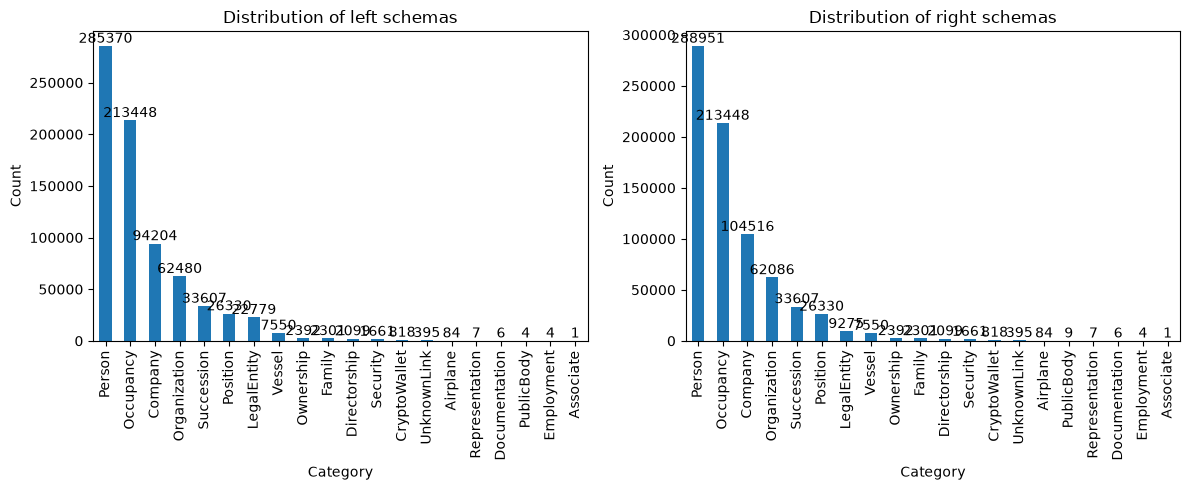

In [112]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left schema
df['left_schema'].value_counts().plot(kind='bar', ax=axes[0])

axes[0].set(
    title='Distribution of left schemas',
    xlabel='Category',
    ylabel='Count'
)

axes[0].bar_label(axes[0].containers[0])

# Right schema
df['right_schema'].value_counts().plot(kind='bar', ax=axes[1])

axes[1].set(
    title='Distribution of right schemas',
    xlabel='Category',
    ylabel='Count'
)

axes[1].bar_label(axes[1].containers[0])

plt.tight_layout()
plt.show()

- We have discrepancies across schema categories, (`right_schema` and `left_schema`)

In [113]:
#or:

df.loc[
    df['left_schema'] != df['right_schema'],
    ['left_schema', 'right_schema']
].value_counts()

left_schema   right_schema
Organization  Company         25849
Company       Organization    21953
LegalEntity   Company          7738
              Organization     4648
              Person           3969
Company       LegalEntity      1314
Organization  LegalEntity      1071
Person        LegalEntity       466
Organization  Person            123
Person        Organization       52
Company       Person             51
Person        Company            44
Organization  PublicBody          8
PublicBody    Organization        4
Company       PublicBody          1
Name: count, dtype: int64

In [ ]:
df[['left_datasets','right_datasets']].head(20)

# 2. Can we trust the labels?

## 2.1 Are there duplicate pairs?

1. Count duplicate ids on `right_id` and `left_id`

In [130]:
df.loc[:,['right_id','left_id']]

,right_id,left_id
0,unsc-2894441,eu-fsf-eu-3298-47
1,unsc-2894441,ofac-11493
2,NK-6pe3A3UzgMBo5uQ6qEiUye,unsc-2894441
3,NK-6pe3A3UzgMBo5uQ6qEiUye,gb-hmt-11052
4,unsc-2971675,eu-fsf-eu-2799-30
...,...,...
755535,NK-i5HsmnwhdAZi7crpRMxuDm,NK-i5HsmnwhdAZi7crpRMxuDm
755536,pk-cnic-3240347507563,pk-cnic-3230415852241
755537,pk-cnic-3240347507563,pk-cnic-1730158775611
755538,pk-cnic-3240347507563,pk-cnic-1310108475041


In [ ]:
df.loc[
    df['right_id']==df['left_id'],
    ['right_id','left_id']
].value_counts()

In [132]:
id_duplicates = df.loc[
    df['right_id']==df['left_id'],
    ['right_id']].count()

id_duplicates/df.count() * 100

judgement                 NaN
left_address              NaN
left_alias                NaN
left_birthDate            NaN
left_caption              NaN
left_country              NaN
left_datasets             NaN
left_firstName            NaN
left_id                   NaN
left_idNumber             NaN
left_lastName             NaN
left_middleName           NaN
left_name                 NaN
left_nationality          NaN
left_schema               NaN
left_topics               NaN
pair_id                   NaN
right_address             NaN
right_alias               NaN
right_birthDate           NaN
right_caption             NaN
right_country             NaN
right_datasets            NaN
right_firstName           NaN
right_id             5.139371
right_idNumber            NaN
right_lastName            NaN
right_middleName          NaN
right_name                NaN
right_nationality         NaN
right_schema              NaN
right_topics              NaN
dtype: float64

In [133]:
PROPS = ["name", "alias", "firstName", "lastName", "birthDate",
         "country", "nationality", "idNumber", "address", "topics"]

presence = pd.DataFrame([
    {
        "field": f,
        "left_present_%": round(100 * (scoped[f"left_{f}"].map(len) > 0).mean(), 1),
        "right_present_%": round(100 * (scoped[f"right_{f}"].map(len) > 0).mean(), 1),
        "both_present_%": round(100 * (
            (scoped[f"left_{f}"].map(len) > 0) & (scoped[f"right_{f}"].map(len) > 0)
        ).mean(), 1),
    }
    for f in PROPS
]).sort_values("both_present_%", ascending=False)
print("how often is each field usable, in-scope rows")
print(presence.to_string(index=False))
print()

lengths = [len(v) for lst in scoped.left_birthDate.head(200_000) for v in lst]
print("birthDate value lengths (4 = year only, 7 = year-month, 10 = full date):")
print(pd.Series(lengths).value_counts().to_dict())
print(f"entities carrying more than one birthDate: "
      f"{100 * (scoped.left_birthDate.map(len) > 1).mean():.1f}%")
print()
print("names held per entity: median %d, p90 %d, max %d" % (
    scoped.left_name.map(len).median(),
    scoped.left_name.map(len).quantile(0.9),
    scoped.left_name.map(len).max()))

NameError: name 'scoped' is not defined

**d. Check for data quality**

Missing values, duplicates, impossible or inconsistent values. Also watch out for outliers and anomalies that may require further investigation. Explain what you found and what you are going to do with the information.


In [128]:
print("=== duplicates and self-pairs ===")
self_pairs = scoped.left_id == scoped.right_id
print(f"an entity paired with itself : {int(self_pairs.sum()):,}")
print("  their labels:", scoped[self_pairs].judgement.value_counts().to_dict())

dups = scoped.duplicated(subset=["left_id", "right_id"], keep=False)
conflict = (scoped[dups].groupby(["left_id", "right_id"]).judgement.nunique() > 1).sum()
print(f"rows involved in repeated pairs: {int(dups.sum()):,}")
print(f"  repeated pairs labelled BOTH positive and negative: {int(conflict)}")

print("\n=== entity reuse (matters for the train/test split) ===")
appearances = pd.concat([scoped.left_id, scoped.right_id]).value_counts()
print(f"distinct entities: {len(appearances):,}")
print(f"appearances per entity: median {appearances.median():.0f}, "
      f"p99 {appearances.quantile(0.99):.0f}, max {appearances.max():,}")

print("\n=== missing and impossible values ===")
for col in ["judgement", "left_caption", "right_caption", "left_id", "right_id"]:
    print(f"  nulls in {col}: {int(scoped[col].isna().sum())}")

print("\n=== cleaning ===")
clean = (scoped[~self_pairs]
         .drop_duplicates(subset=["left_id", "right_id"])
         .reset_index(drop=True))
print(f"{len(pairs):,} raw  ->  {len(scoped):,} in scope  ->  {len(clean):,} after cleaning")
print("label balance after cleaning:",
      clean.judgement.value_counts(normalize=True).round(3).to_dict())

print("\n=== a feature that is too good to be true ===")
shared_source = clean.apply(
    lambda r: len(set(r.left_datasets) & set(r.right_datasets)) > 0, axis=1)
print(pd.crosstab(shared_source, clean.judgement, normalize="index").round(3))
rule = (~shared_source) == (clean.judgement == "positive")
print(f"accuracy of 'different source lists => same entity', using no names at all: "
      f"{100 * rule.mean():.1f}%")

print("\n=== identical names that are different entities ===")
identical = (clean.left_caption.str.strip().str.casefold()
             == clean.right_caption.str.strip().str.casefold())
print(f"negative pairs with identical names: "
      f"{int((identical & (clean.judgement == 'negative')).sum()):,}")

print("\n=== how far does birth date get us ===")
def birthdate_agreement(row):
    left, right = set(row.left_birthDate), set(row.right_birthDate)
    if not left or not right:
        return "missing on one side"
    if left & right:
        return "exact match"
    if {v[:4] for v in left} & {v[:4] for v in right}:
        return "same year only"
    return "conflict"

clean["bd"] = clean.apply(birthdate_agreement, axis=1)
print(pd.crosstab(clean.bd, clean.judgement, normalize="index").round(3))
print("\nrows in each group:", clean.bd.value_counts().to_dict())

=== duplicates and self-pairs ===


NameError: name 'scoped' is not defined